# <span style="color:green"> Laboratorio di Simulazione Numerica </span>
## <span style="color:orange"> Tommaso Cardano Chiezzi</span>

# Esercitazione 11 — Neural Networks and Regression


L'obiettivo dell'esercitazione è studiare l'applicazione delle reti neurali artificiali (Artificial Neural Networks, ANN) a problemi di regressione.

Verranno analizzati tre problemi di complessità crescente:

- **Esercizio 11.1 — Regressione lineare:** studio dell'influenza del numero di epoche, della dimensione del training set e del rumore statistico sulla qualità della regressione.
- **Esercizio 11.2 — Regressione polinomiale:** approssimazione di una funzione polinomiale di terzo grado mediante una rete neurale.
- **Esercizio 11.3 — Regressione non lineare bidimensionale:** approssimazione di una funzione trigonometrica dipendente da due variabili.

Per ciascun esercizio verranno descritti il modello utilizzato, la procedura di addestramento e i risultati ottenuti, con particolare attenzione alla capacità di generalizzazione della rete neurale.

Le simulazioni saranno implementate in Python mediante le librerie NumPy, Matplotlib e TensorFlow/Keras.

---

# Esercizio 11.1 — Regressione lineare con una rete neurale

## Obiettivo

L'obiettivo è studiare la capacità di una rete neurale artificiale di eseguire una regressione lineare su dati affetti da rumore statistico, analizzando l'influenza dei seguenti parametri:

- **Numero di epoche** ($N_{\mathrm{epochs}}$): numero di iterazioni complete sul dataset di addestramento.
- **Dimensione del training set** ($N_{\mathrm{train}}$): numero di osservazioni utilizzate per addestrare il modello.
- **Deviazione standard del rumore** ($\sigma$): intensità delle fluttuazioni casuali presenti nei dati.

## Modello teorico e generazione dei dati

Si considera la funzione lineare:

$$
f(x)=mx+b=2x+1
$$

dove $m=2$ rappresenta il coefficiente angolare e $b=1$ l'intercetta.

I dati vengono generati aggiungendo alla funzione un rumore gaussiano indipendente:

$$
y_i=f(x_i)+\eta_i
$$

con:

$$
\eta_i\sim\mathcal{N}(0,\sigma^2)
$$

Il rumore è caratterizzato dalle proprietà:

$$
\langle\eta_i\rangle=0,
\qquad
\langle\eta_i\eta_j\rangle=\sigma^2\delta_{ij}
$$

Il valore di $\sigma$ controlla quindi la dispersione delle osservazioni rispetto alla retta teorica.

## Architettura della rete neurale

Poiché la funzione da approssimare è lineare, è sufficiente utilizzare una rete neurale composta da un singolo neurone, con funzione di attivazione identità.

L'output del modello è:

$$
\hat{y}(x)=wx+c
$$

dove $w$ e $c$ sono i parametri addestrabili della rete.

L'addestramento consiste nel determinare i valori ottimali dei parametri affinché:

$$
w\simeq 2,
\qquad
c\simeq 1
$$

## Addestramento e valutazione

Il dataset viene suddiviso in due insiemi indipendenti:

- **Training set:** utilizzato per ottimizzare i parametri della rete.
- **Validation set:** utilizzato per valutare la capacità di generalizzazione su dati non impiegati nell'addestramento.

Come funzione di perdita viene utilizzato il **Mean Squared Error (MSE)**:

$$
\mathrm{MSE}=\frac{1}{N}\sum_{i=1}^{N}(y_i-\hat{y}_i)^2
$$

La qualità della regressione viene analizzata confrontando:

1. I parametri appresi $w$ e $c$ con quelli teorici.
2. L'andamento del training MSE e del validation MSE durante l'addestramento.
3. Le predizioni della rete con la funzione teorica $f(x)=2x+1$.

In presenza di rumore gaussiano, anche una regressione perfetta presenta un MSE atteso pari a $\sigma^2$ rispetto a nuove osservazioni rumorose. L'errore rispetto alla funzione teorica, invece, può tendere a zero.

La variazione dei parametri richiesti dall'esercizio permetterà di studiare la convergenza dell'addestramento, l'effetto delle fluttuazioni statistiche e la capacità di generalizzazione della rete.

In [1]:

# ============================================================
# ESERCIZIO 11.1 - Regressione lineare
# ============================================================

# Librerie per il calcolo numerico e la visualizzazione
import numpy as np
import matplotlib.pyplot as plt

# Librerie per la costruzione e l'addestramento della rete neurale
import tensorflow as tf
from tensorflow import keras

# Seme per la riproducibilità dei risultati
keras.utils.set_random_seed(0)

# Parametri della funzione teorica: f(x) = m*x + b
m_true = 2.0
b_true = 1.0

# Parametri iniziali della simulazione
N_train = 500      # Numero di dati di training
N_valid = 50       # Numero di dati di validazione
sigma = 0.2        # Deviazione standard del rumore gaussiano

# Parametri iniziali dell'addestramento
N_epochs = 30      # Numero di epoche
batch_size = 32    # Numero di osservazioni per batch


In [2]:

# ============================================================
# Generazione dei dati di training e validazione
# ============================================================

# Inizializzazione del generatore di numeri casuali
rng = np.random.default_rng(0)

# Generazione degli input uniformemente distribuiti in [-1, 1]
x_train = rng.uniform(-1.0, 1.0, N_train)
x_valid = rng.uniform(-1.0, 1.0, N_valid)

# Ordinamento degli input di validazione per i grafici
x_valid.sort()

# Valori teorici della funzione lineare
y_target = m_true * x_valid + b_true

# Generazione dei dati con rumore gaussiano
y_train = m_true * x_train + b_true + rng.normal(
    0.0, sigma, N_train
)

y_valid = y_target + rng.normal(
    0.0, sigma, N_valid
)

# Informazioni sui dataset generati
print(f"Training set:   {len(x_train)} punti")
print(f"Validation set: {len(x_valid)} punti")
print(f"Rumore:         sigma = {sigma}")


Training set:   500 punti
Validation set: 50 punti
Rumore:         sigma = 0.2


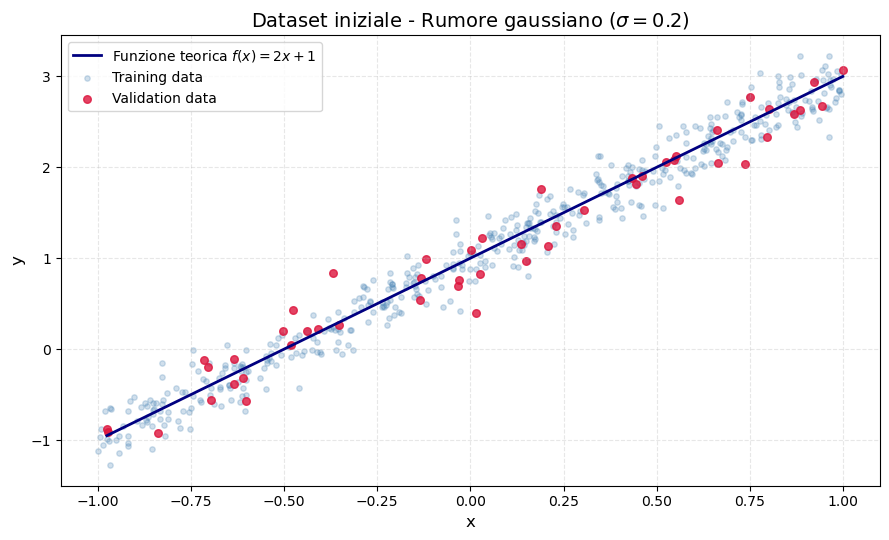

In [3]:

# ============================================================
# Visualizzazione dei dati di training e validazione
# ============================================================

plt.figure(figsize=(9, 5.5))

# Funzione lineare teorica
plt.plot(x_valid, y_target, color='navy', linewidth=2,
         label=r'Funzione teorica $f(x)=2x+1$')

# Dati di training
plt.scatter(x_train, y_train, color='steelblue', s=15,
            alpha=0.25, label='Training data')

# Dati di validazione
plt.scatter(x_valid, y_valid, color='crimson', s=30,
            alpha=0.8, label='Validation data')

# Personalizzazione del grafico
plt.xlabel('x', fontsize=12)
plt.ylabel('y', fontsize=12)
plt.title(r'Dataset iniziale - Rumore gaussiano ($\sigma=0.2$)',
          fontsize=14)

plt.legend(fontsize=10)
plt.grid(True, linestyle='--', alpha=0.3)
plt.tight_layout()
plt.show()


In [4]:

# ============================================================
# Costruzione e compilazione della rete neurale
# ============================================================

# Adattamento degli input alla forma richiesta da Keras
x_train_nn = x_train.reshape(-1, 1)
x_valid_nn = x_valid.reshape(-1, 1)

# Definizione della rete neurale
model = keras.Sequential([
    keras.Input(shape=(1,)),
    keras.layers.Dense(1, activation='linear')
])

# Compilazione del modello
model.compile(
    optimizer='sgd',
    loss='mse',
    metrics=['mse']
)

# Visualizzazione dell'architettura
model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense (Dense)                        │ (None, 1)                   │               2 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 2 (8.00 B)

 Trainable params: 2 (8.00 B)

 Non-trainable params: 0 (0.00 B)

In [5]:

# ============================================================
# Addestramento della rete neurale
# ============================================================

# Addestramento del modello sui dati di training
history = model.fit(
    x=x_train_nn,
    y=y_train,
    batch_size=batch_size,
    epochs=N_epochs,
    shuffle=True,
    validation_data=(x_valid_nn, y_valid),
    verbose=1
)


Epoch 1/30
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 31ms/step - loss: 2.0728 - mse: 2.0728 - val_loss: 1.5169 - val_mse: 1.5169
Epoch 2/30
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 1.3878 - mse: 1.3878 - val_loss: 1.0300 - val_mse: 1.0300
Epoch 3/30
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.9752 - mse: 0.9752 - val_loss: 0.7332 - val_mse: 0.7332
Epoch 4/30
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.7152 - mse: 0.7152 - val_loss: 0.5437 - val_mse: 0.5437
Epoch 5/30
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.5433 - mse: 0.5433 - val_loss: 0.4170 - val_mse: 0.4170
Epoch 6/30
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.4243 - mse: 0.4243 - val_loss: 0.3283 - val_mse: 0.3283
Epoch 7/30
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 0.3383 - mse: 0.3383 - val_loss: 0.2640 - val_mse: 0.2640
Epoch 8/30
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 0.2742 - mse: 0.2742 - val_loss: 0.2159 - val_mse: 0.2159
Epoch 9/30
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.2252 

In [6]:

# ============================================================
# Estrazione e confronto dei parametri della rete neurale
# ============================================================

# Estrazione del peso e del bias del neurone
weights, biases = model.get_weights()

w = weights[0, 0]
b = biases[0]

# Calcolo degli scostamenti rispetto ai valori teorici
delta_w = abs(w - m_true)
delta_b = abs(b - b_true)

# Stampa dei risultati
print("PARAMETRI DELLA REGRESSIONE")
print("-" * 45)

print(f"Peso teorico:       {m_true:.6f}")
print(f"Peso appreso:       {w:.6f}")
print(f"Errore assoluto:    {delta_w:.6f}")

print()

print(f"Bias teorico:       {b_true:.6f}")
print(f"Bias appreso:       {b:.6f}")
print(f"Errore assoluto:    {delta_b:.6f}")

print("-" * 45)
print(f"Funzione appresa: y = {w:.4f}x + {b:.4f}")


PARAMETRI DELLA REGRESSIONE
---------------------------------------------
Peso teorico:       2.000000
Peso appreso:       1.925502
Errore assoluto:    0.074498

Bias teorico:       1.000000
Bias appreso:       0.987958
Errore assoluto:    0.012042
---------------------------------------------
Funzione appresa: y = 1.9255x + 0.9880


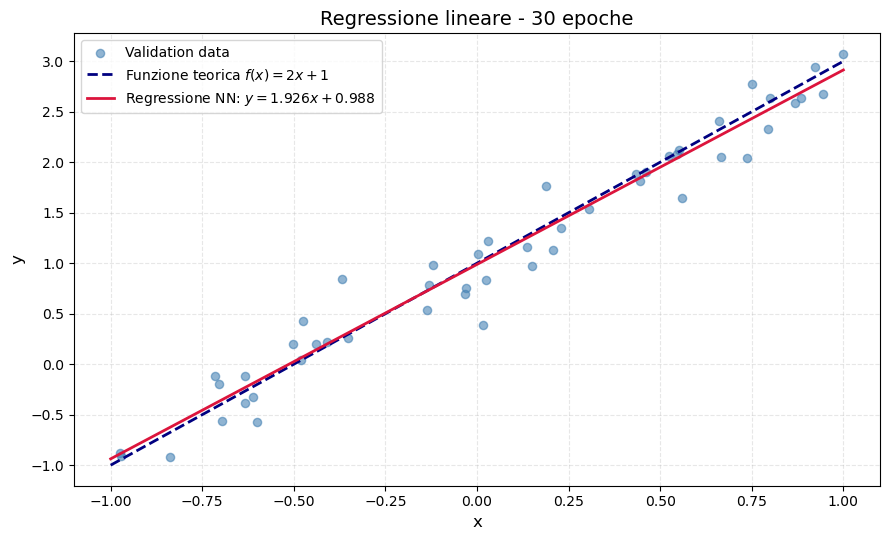

In [7]:

# ============================================================
# Confronto tra funzione teorica e regressione neurale
# ============================================================

# Generazione di punti equispaziati per rappresentare le rette
x_plot = np.linspace(-1.0, 1.0, 300)

# Calcolo della funzione teorica
y_theory = m_true * x_plot + b_true

# Predizioni della rete neurale
y_pred = model.predict(x_plot.reshape(-1, 1), verbose=0).flatten()

# Creazione del grafico
plt.figure(figsize=(9, 5.5))

# Dati di validazione
plt.scatter(x_valid, y_valid, color='steelblue', s=35,
            alpha=0.6, label='Validation data', zorder=2)

# Funzione teorica
plt.plot(x_plot, y_theory, color='navy', linewidth=2,
         linestyle='--', label=r'Funzione teorica $f(x)=2x+1$')

# Funzione appresa dalla rete
plt.plot(x_plot, y_pred, color='crimson', linewidth=2,
         label=fr'Regressione NN: $y={w:.3f}x+{b:.3f}$')

# Personalizzazione del grafico
plt.xlabel('x', fontsize=12)
plt.ylabel('y', fontsize=12)
plt.title(f'Regressione lineare - {N_epochs} epoche',
          fontsize=14)

plt.legend(fontsize=10)
plt.grid(True, linestyle='--', alpha=0.3)
plt.tight_layout()
plt.show()


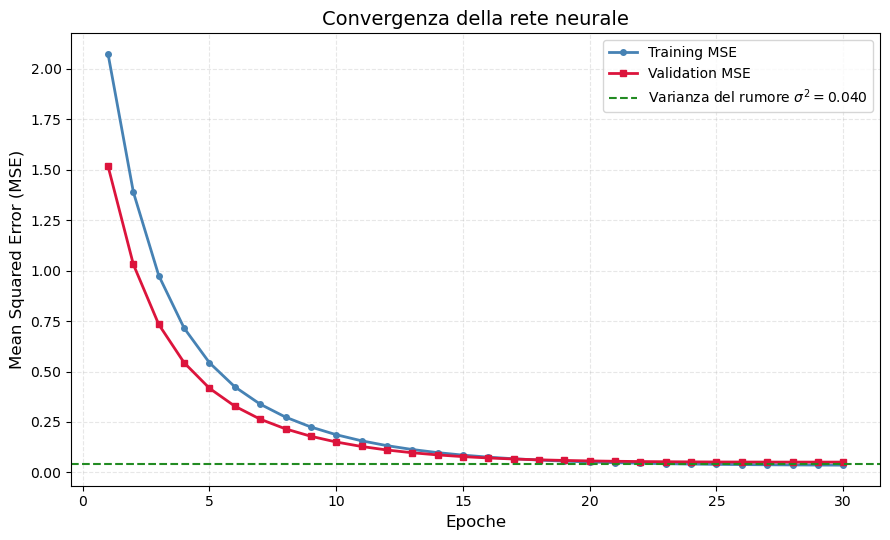

Training MSE finale:   0.036209
Validation MSE finale: 0.051367
Varianza del rumore:   0.040000


In [8]:

# ============================================================
# Andamento della funzione di perdita durante il training
# ============================================================

# Estrazione degli errori registrati durante l'addestramento
train_loss = history.history['loss']
valid_loss = history.history['val_loss']

# Numero delle epoche
epochs = np.arange(1, len(train_loss) + 1)

# Valore teorico dell'MSE dovuto al rumore gaussiano
mse_noise = sigma**2

# Creazione del grafico
plt.figure(figsize=(9, 5.5))

# Errore sul training set
plt.plot(epochs, train_loss, color='steelblue', linewidth=2,
         marker='o', markersize=4, label='Training MSE')

# Errore sul validation set
plt.plot(epochs, valid_loss, color='crimson', linewidth=2,
         marker='s', markersize=4, label='Validation MSE')

# Livello teorico del rumore
plt.axhline(y=mse_noise, color='forestgreen',
            linestyle='--', linewidth=1.5,
            label=fr'Varianza del rumore $\sigma^2={mse_noise:.3f}$')

# Personalizzazione del grafico
plt.xlabel('Epoche', fontsize=12)
plt.ylabel('Mean Squared Error (MSE)', fontsize=12)
plt.title('Convergenza della rete neurale', fontsize=14)

plt.legend(fontsize=10)
plt.grid(True, linestyle='--', alpha=0.3)
plt.tight_layout()
plt.show()

# Stampa degli errori finali
print(f"Training MSE finale:   {train_loss[-1]:.6f}")
print(f"Validation MSE finale: {valid_loss[-1]:.6f}")
print(f"Varianza del rumore:   {mse_noise:.6f}")



### Analisi della convergenza e influenza del numero di epoche

Dal grafico precedente si osserva una rapida diminuzione del Training MSE e del Validation MSE, seguita da una progressiva stabilizzazione dopo circa 20–25 epoche.

Gli errori finali risultano rispettivamente pari a **0.0362** e **0.0514**, entrambi prossimi alla varianza teorica del rumore gaussiano, $\sigma^2=0.04$. La differenza tra i due valori è contenuta e non evidenzia un significativo fenomeno di overfitting.

Per verificare se un addestramento più prolungato possa migliorare ulteriormente la regressione, si analizza la dipendenza dell'MSE e dei parametri appresi dal **numero di epoche**, mantenendo invariati il dataset, l'architettura della rete e l'intensità del rumore.


  Epoche    Train MSE    Valid MSE        |w-2|        |b-1|
--------------------------------------------------------------
       5     0.471468     0.416972     1.100435     0.140347
      10     0.169356     0.150884     0.638241     0.000991
      20     0.049850     0.057241     0.218553     0.000680
      30     0.035944     0.051367     0.074498     0.012042
      50     0.034185     0.053268     0.007408     0.018684
     100     0.034178     0.053754     0.001686     0.019594
     150     0.034178     0.053757     0.001732     0.019598


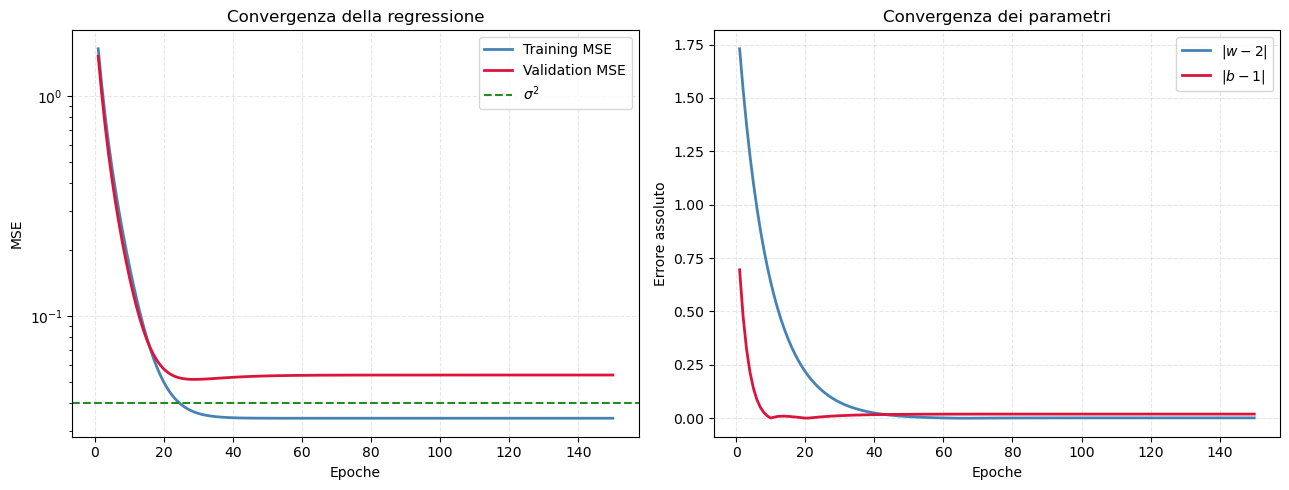

In [9]:

# ============================================================
# Studio della dipendenza dal numero di epoche
# ============================================================

# Numero di epoche da confrontare
epochs_test = [5, 10, 20, 30, 50, 100, 150]

# Ripristino del seme per una nuova inizializzazione riproducibile
keras.utils.set_random_seed(0)

# Costruzione di una nuova rete con la stessa architettura
model_epochs = keras.Sequential([
    keras.Input(shape=(1,)),
    keras.layers.Dense(1, activation='linear')
])

model_epochs.compile(optimizer='sgd', loss='mse')


# Callback per registrare i parametri e gli errori a ogni epoca
class TrainingMonitor(keras.callbacks.Callback):

    def on_train_begin(self, logs=None):
        self.w_values = []
        self.b_values = []
        self.train_mse = []
        self.valid_mse = []

    def on_epoch_end(self, epoch, logs=None):

        # Estrazione dei parametri correnti
        weights, biases = self.model.get_weights()
        w = float(weights[0, 0])
        b = float(biases[0])

        # Predizioni sui dataset fissati
        pred_train = w * x_train + b
        pred_valid = w * x_valid + b

        # Registrazione dei parametri e degli MSE
        self.w_values.append(w)
        self.b_values.append(b)
        self.train_mse.append(np.mean((y_train - pred_train)**2))
        self.valid_mse.append(np.mean((y_valid - pred_valid)**2))


# Addestramento fino al numero massimo di epoche
monitor = TrainingMonitor()

model_epochs.fit(
    x_train_nn, y_train,
    batch_size=batch_size,
    epochs=max(epochs_test),
    shuffle=True,
    verbose=0,
    callbacks=[monitor]
)

# Stampa dei risultati alle epoche selezionate
print(f"{'Epoche':>8} {'Train MSE':>12} {'Valid MSE':>12} "
      f"{'|w-2|':>12} {'|b-1|':>12}")
print("-" * 62)

for n in epochs_test:
    i = n - 1
    print(f"{n:8d} {monitor.train_mse[i]:12.6f} "
          f"{monitor.valid_mse[i]:12.6f} "
          f"{abs(monitor.w_values[i] - m_true):12.6f} "
          f"{abs(monitor.b_values[i] - b_true):12.6f}")


# ============================================================
# Visualizzazione dei risultati
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

epochs_range = np.arange(1, max(epochs_test) + 1)

# Grafico 1: andamento degli errori
axes[0].plot(epochs_range, monitor.train_mse,
             color='steelblue', linewidth=2, label='Training MSE')

axes[0].plot(epochs_range, monitor.valid_mse,
             color='crimson', linewidth=2, label='Validation MSE')

axes[0].axhline(sigma**2, color='forestgreen',
                linestyle='--', label=r'$\sigma^2$')

axes[0].set_xlabel('Epoche')
axes[0].set_ylabel('MSE')
axes[0].set_title('Convergenza della regressione')
axes[0].set_yscale('log')
axes[0].legend()
axes[0].grid(True, linestyle='--', alpha=0.3)

# Grafico 2: scostamento dei parametri dai valori teorici
axes[1].plot(epochs_range,
             np.abs(np.array(monitor.w_values) - m_true),
             color='steelblue', linewidth=2,
             label=r'$|w-2|$')

axes[1].plot(epochs_range,
             np.abs(np.array(monitor.b_values) - b_true),
             color='crimson', linewidth=2,
             label=r'$|b-1|$')

axes[1].set_xlabel('Epoche')
axes[1].set_ylabel('Errore assoluto')
axes[1].set_title('Convergenza dei parametri')
axes[1].legend()
axes[1].grid(True, linestyle='--', alpha=0.3)

plt.tight_layout()
plt.show()



### Risultati: influenza del numero di epoche

L'aumento del numero di epoche determina inizialmente una rapida diminuzione del Training MSE e del Validation MSE, indicando una progressiva convergenza della rete neurale verso la funzione teorica.

Dopo circa 30–50 epoche, il Training MSE si stabilizza intorno a $0.0342$, mentre il Validation MSE assume valori prossimi a $0.054$, confrontabili con la varianza teorica del rumore $\sigma^2=0.04$.

Anche i parametri della regressione convergono verso i valori attesi. Dopo 150 epoche si ottengono:

$$
|w-2| \simeq 0.0017,
\qquad
|b-1| \simeq 0.0196
$$

Si osserva inoltre un leggero aumento del Validation MSE dopo le prime 30 epoche, nonostante la continua diminuzione del Training MSE. Tale comportamento può essere attribuito alle fluttuazioni statistiche del campione di validazione e non costituisce, da solo, una prova significativa di overfitting.

**In conclusione**, 30 epoche risultano sufficienti per ottenere una buona approssimazione della funzione, mentre circa 50–100 epoche permettono di raggiungere una convergenza più completa dei parametri. Un ulteriore aumento del numero di epoche non produce miglioramenti apprezzabili.

### Influenza della dimensione del training set

Si procede analizzando la dipendenza della qualità della regressione dal numero di dati utilizzati durante l'addestramento, mantenendo fissati il rumore gaussiano e l'architettura della rete neurale.


 N train    Train MSE    Valid MSE  MSE teorico      |w-2|      |b-1|
---------------------------------------------------------------------------
       5     0.023688     0.071394     0.025361   0.066228   0.154584
      10     0.036825     0.061950     0.007392   0.091891   0.067614
      20     0.025743     0.060842     0.002744   0.083452   0.020442
      50     0.028229     0.057300     0.000553   0.039704   0.005192
     100     0.034750     0.055042     0.000684   0.022537   0.022669
     200     0.035468     0.053744     0.000088   0.007539   0.008328
     500     0.034172     0.053625     0.000324   0.001514   0.017978
    1000     0.037340     0.053817     0.000230   0.000231   0.015166
    2000     0.039576     0.053440     0.000172   0.009656   0.011886


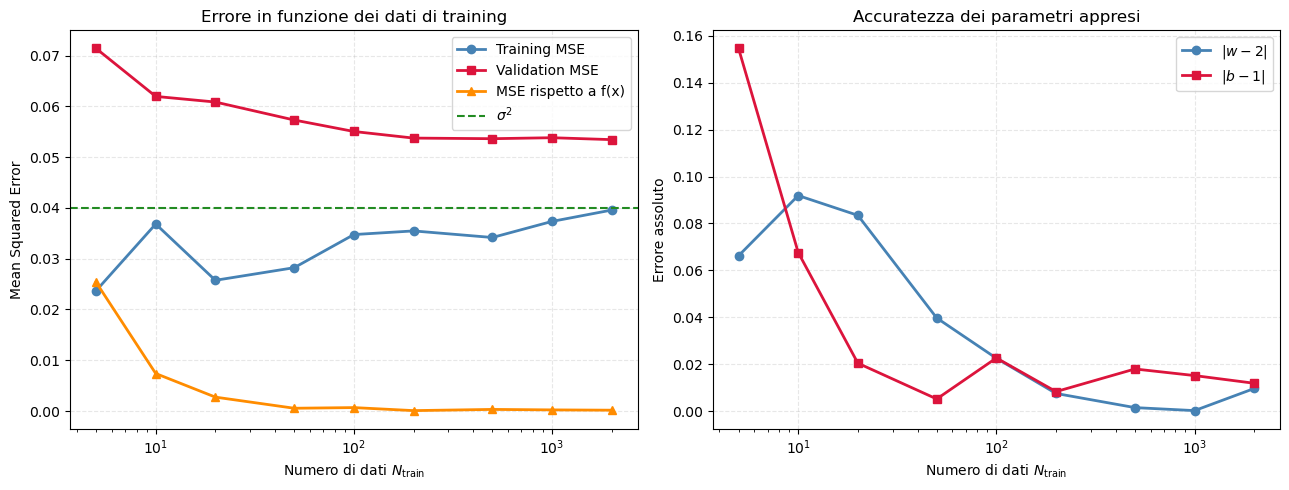

In [13]:

# ============================================================
# Studio della dipendenza dalla dimensione del training set
# ============================================================

# Dimensioni dei training set da confrontare
N_train_values = [5, 10, 20, 50, 100, 200, 500, 1000, 2000]

# Generazione di ulteriori dati per costruire il dataset più grande
rng_extra = np.random.default_rng(1234)

N_extra = max(N_train_values) - len(x_train)

x_extra = rng_extra.uniform(-1.0, 1.0, N_extra)
y_extra = m_true * x_extra + b_true + rng_extra.normal(
    0.0, sigma, N_extra
)

# Dataset comune: ogni campione contiene i punti del precedente
x_pool = np.concatenate((x_train, x_extra))
y_pool = np.concatenate((y_train, y_extra))

# Griglia per valutare l'errore rispetto alla funzione teorica
x_grid = np.linspace(-1.0, 1.0, 1000)
y_grid = m_true * x_grid + b_true

# Array per la memorizzazione dei risultati
mse_train = []
mse_valid = []
mse_theory = []
error_w = []
error_b = []

# Addestramento per diverse dimensioni del dataset
for n in N_train_values:

    # Selezione dei primi n dati
    x_subset = x_pool[:n].reshape(-1, 1)
    y_subset = y_pool[:n]

    # Stessa inizializzazione per ogni rete
    keras.utils.set_random_seed(42)

    # Costruzione del modello
    model_n = keras.Sequential([
        keras.Input(shape=(1,)),
        keras.layers.Dense(1, activation='linear')
    ])

    model_n.compile(
        optimizer=keras.optimizers.SGD(learning_rate=0.1),
        loss='mse'
    )

    # Addestramento full-batch
    model_n.fit(
        x_subset, y_subset,
        epochs=200,
        batch_size=n,
        shuffle=False,
        verbose=0
    )

    # Estrazione dei parametri appresi
    weights, biases = model_n.get_weights()
    w_n = float(weights[0, 0])
    b_n = float(biases[0])

    # Calcolo delle predizioni
    pred_train = w_n * x_subset.flatten() + b_n
    pred_valid = w_n * x_valid + b_n
    pred_theory = w_n * x_grid + b_n

    # Calcolo degli errori
    mse_train.append(np.mean((y_subset - pred_train)**2))
    mse_valid.append(np.mean((y_valid - pred_valid)**2))
    mse_theory.append(np.mean((y_grid - pred_theory)**2))

    error_w.append(abs(w_n - m_true))
    error_b.append(abs(b_n - b_true))


# ============================================================
# Tabella dei risultati
# ============================================================

print(f"{'N train':>8} {'Train MSE':>12} {'Valid MSE':>12} "
      f"{'MSE teorico':>12} {'|w-2|':>10} {'|b-1|':>10}")
print("-" * 75)

for i, n in enumerate(N_train_values):
    print(f"{n:8d} {mse_train[i]:12.6f} {mse_valid[i]:12.6f} "
          f"{mse_theory[i]:12.6f} {error_w[i]:10.6f} "
          f"{error_b[i]:10.6f}")


# ============================================================
# Visualizzazione dei risultati
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Grafico 1: errori della regressione
axes[0].plot(N_train_values, mse_train, 'o-',
             color='steelblue', linewidth=2, label='Training MSE')

axes[0].plot(N_train_values, mse_valid, 's-',
             color='crimson', linewidth=2, label='Validation MSE')

axes[0].plot(N_train_values, mse_theory, '^-',
             color='darkorange', linewidth=2,
             label='MSE rispetto a f(x)')

axes[0].axhline(sigma**2, color='forestgreen',
                linestyle='--', label=r'$\sigma^2$')

axes[0].set_xscale('log')
axes[0].set_xlabel(r'Numero di dati $N_{\mathrm{train}}$')
axes[0].set_ylabel('Mean Squared Error')
axes[0].set_title('Errore in funzione dei dati di training')
axes[0].legend()
axes[0].grid(True, linestyle='--', alpha=0.3)

# Grafico 2: errori sui parametri
axes[1].plot(N_train_values, error_w, 'o-',
             color='steelblue', linewidth=2, label=r'$|w-2|$')

axes[1].plot(N_train_values, error_b, 's-',
             color='crimson', linewidth=2, label=r'$|b-1|$')

axes[1].set_xscale('log')
axes[1].set_xlabel(r'Numero di dati $N_{\mathrm{train}}$')
axes[1].set_ylabel('Errore assoluto')
axes[1].set_title('Accuratezza dei parametri appresi')
axes[1].legend()
axes[1].grid(True, linestyle='--', alpha=0.3)

plt.tight_layout()
plt.show()



### Risultati: influenza della dimensione del training set

L'aumento del numero di dati di training determina un miglioramento complessivo della capacità della rete neurale di ricostruire la funzione teorica.

In particolare, l'MSE rispetto alla funzione esatta diminuisce da circa $2.74\times10^{-3}$, con 20 osservazioni, a $1.72\times10^{-4}$, con 2000 osservazioni.

Il Training MSE tende invece ad aumentare, avvicinandosi alla varianza teorica del rumore $\sigma^2=0.04$. Questo comportamento è coerente con una maggiore rappresentatività statistica del campione: con pochi dati, il modello può adattarsi particolarmente bene alle fluttuazioni delle osservazioni disponibili.

Il Validation MSE diminuisce inizialmente e si stabilizza intorno a $0.0535$. Il valore leggermente superiore a $\sigma^2$ è compatibile con le fluttuazioni statistiche del validation set, costituito da un numero finito di osservazioni.

Anche gli scostamenti dei parametri $w$ e $b$ dai valori teorici mostrano una tendenza complessiva alla diminuzione, sebbene non monotona.

**In conclusione**, aumentando la dimensione del training set si riduce generalmente l'incertezza nella stima dei parametri e migliora la ricostruzione della funzione originale. Le fluttuazioni osservate sono compatibili con la natura statistica del problema.



### Influenza del rumore gaussiano

Si procede infine analizzando l'effetto della deviazione standard $\sigma$ del rumore sui dati, mantenendo fissati il numero di osservazioni e l'architettura della rete neurale.

L'obiettivo è verificare come l'intensità delle fluttuazioni statistiche influenzi la precisione della regressione e la capacità di ricostruire i parametri teorici.


  Sigma    Train MSE    Valid MSE     MSE f(x)      |w-2|      |b-1|
----------------------------------------------------------------------
   0.00     0.000000     0.000000     0.000000   0.000001   0.000000
   0.10     0.010958     0.012152     0.000010   0.001901   0.003035
   0.20     0.043830     0.048608     0.000042   0.003804   0.006069
   0.40     0.175320     0.194434     0.000167   0.007610   0.012137
   0.60     0.394470     0.437476     0.000375   0.011416   0.018206
   0.80     0.701281     0.777735     0.000667   0.015222   0.024275


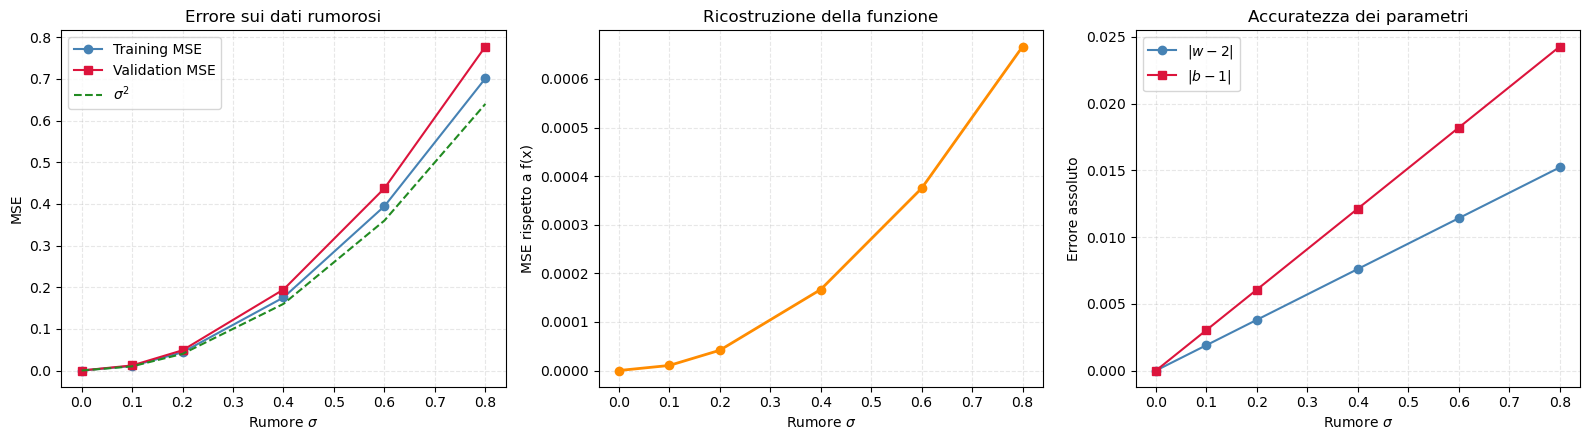

In [11]:

# ============================================================
# Studio della dipendenza dall'intensità del rumore gaussiano
# ============================================================

# Valori della deviazione standard da confrontare
sigma_values = [0.0, 0.1, 0.2, 0.4, 0.6, 0.8]

# Generatore casuale per ottenere rumore riproducibile
rng_sigma = np.random.default_rng(2026)

# Estrazione di rumore gaussiano standard
z_train = rng_sigma.normal(0.0, 1.0, N_train)
z_valid = rng_sigma.normal(0.0, 1.0, N_valid)

# Array per memorizzare i risultati
train_mse_sigma = []
valid_mse_sigma = []
theory_mse_sigma = []
error_w_sigma = []
error_b_sigma = []

# Valori teorici privi di rumore
y_train_exact = m_true * x_train + b_true
y_valid_exact = m_true * x_valid + b_true

# Addestramento per diverse intensità di rumore
for sigma_i in sigma_values:

    # Generazione dei dati rumorosi
    y_train_sigma = y_train_exact + sigma_i * z_train
    y_valid_sigma = y_valid_exact + sigma_i * z_valid

    # Inizializzazione riproducibile della rete
    keras.utils.set_random_seed(42)

    model_sigma = keras.Sequential([
        keras.Input(shape=(1,)),
        keras.layers.Dense(1, activation='linear')
    ])

    model_sigma.compile(
        optimizer=keras.optimizers.SGD(learning_rate=0.1),
        loss='mse'
    )

    # Addestramento full-batch
    model_sigma.fit(
        x_train_nn, y_train_sigma,
        batch_size=N_train,
        epochs=200,
        shuffle=False,
        verbose=0
    )

    # Estrazione dei parametri
    weights, biases = model_sigma.get_weights()
    w_s = float(weights[0, 0])
    b_s = float(biases[0])

    # Predizioni della rete
    pred_train = w_s * x_train + b_s
    pred_valid = w_s * x_valid + b_s
    pred_theory = w_s * x_grid + b_s

    # Calcolo degli MSE
    train_mse_sigma.append(
        np.mean((y_train_sigma - pred_train)**2)
    )

    valid_mse_sigma.append(
        np.mean((y_valid_sigma - pred_valid)**2)
    )

    theory_mse_sigma.append(
        np.mean((y_grid - pred_theory)**2)
    )

    # Errori assoluti sui parametri
    error_w_sigma.append(abs(w_s - m_true))
    error_b_sigma.append(abs(b_s - b_true))


# ============================================================
# Tabella dei risultati
# ============================================================

print(f"{'Sigma':>7} {'Train MSE':>12} {'Valid MSE':>12} "
      f"{'MSE f(x)':>12} {'|w-2|':>10} {'|b-1|':>10}")
print("-" * 70)

for i, s in enumerate(sigma_values):
    print(f"{s:7.2f} {train_mse_sigma[i]:12.6f} "
          f"{valid_mse_sigma[i]:12.6f} "
          f"{theory_mse_sigma[i]:12.6f} "
          f"{error_w_sigma[i]:10.6f} "
          f"{error_b_sigma[i]:10.6f}")


# ============================================================
# Visualizzazione dei risultati
# ============================================================

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

# Grafico 1: MSE sui dati rumorosi
axes[0].plot(sigma_values, train_mse_sigma, 'o-',
             color='steelblue', label='Training MSE')

axes[0].plot(sigma_values, valid_mse_sigma, 's-',
             color='crimson', label='Validation MSE')

axes[0].plot(sigma_values, np.array(sigma_values)**2,
             '--', color='forestgreen', label=r'$\sigma^2$')

axes[0].set_xlabel(r'Rumore $\sigma$')
axes[0].set_ylabel('MSE')
axes[0].set_title('Errore sui dati rumorosi')
axes[0].legend()
axes[0].grid(True, linestyle='--', alpha=0.3)

# Grafico 2: errore rispetto alla funzione esatta
axes[1].plot(sigma_values, theory_mse_sigma, 'o-',
             color='darkorange', linewidth=2)

axes[1].set_xlabel(r'Rumore $\sigma$')
axes[1].set_ylabel('MSE rispetto a f(x)')
axes[1].set_title('Ricostruzione della funzione')
axes[1].grid(True, linestyle='--', alpha=0.3)

# Grafico 3: errori sui parametri appresi
axes[2].plot(sigma_values, error_w_sigma, 'o-',
             color='steelblue', label=r'$|w-2|$')

axes[2].plot(sigma_values, error_b_sigma, 's-',
             color='crimson', label=r'$|b-1|$')

axes[2].set_xlabel(r'Rumore $\sigma$')
axes[2].set_ylabel('Errore assoluto')
axes[2].set_title('Accuratezza dei parametri')
axes[2].legend()
axes[2].grid(True, linestyle='--', alpha=0.3)

plt.tight_layout()
plt.show()



### Risultati: influenza del rumore gaussiano

L'aumento della deviazione standard $\sigma$ determina un incremento del Training MSE e del Validation MSE, con un andamento approssimativamente proporzionale a $\sigma^2$, come previsto dalla teoria.

Anche l'MSE rispetto alla funzione esatta cresce con l'intensità del rumore, pur rimanendo significativamente inferiore agli errori sui dati rumorosi. Gli scostamenti dei parametri appresi dai valori teorici aumentano invece approssimativamente in modo lineare con $\sigma$.


**In conclusione**, il rumore statistico limita la precisione della stima dei parametri, ma non impedisce alla rete di identificare la relazione lineare sottostante.

### Regressione finale con i parametri selezionati

Sulla base delle analisi precedenti, si selezionano:

- **$N_{\mathrm{train}}=2000$**: dimensione che ha prodotto il minore MSE rispetto alla funzione teorica tra quelle esaminate.
- **$N_{\mathrm{epochs}}=100$**: numero di epoche sufficiente a raggiungere una convergenza sostanzialmente completa.
- **$\sigma=0.2$**: intensità del rumore utilizzata come riferimento iniziale.

Si procede quindi a un nuovo addestramento della rete con questi parametri, confrontando la regressione ottenuta con la funzione teorica $f(x)=2x+1$.

La configurazione selezionata è la migliore tra quelle esaminate secondo i criteri considerati, senza rappresentare necessariamente un ottimo globale.


REGRESSIONE FINALE
---------------------------------------------
Training data:  2000
Epoche:        100
Rumore sigma:  0.20

w = 1.989576  (teorico: 2)
b = 0.988132  (teorico: 1)

Training MSE:  0.039576
Validation MSE:0.053400
MSE teorico:   0.00017714


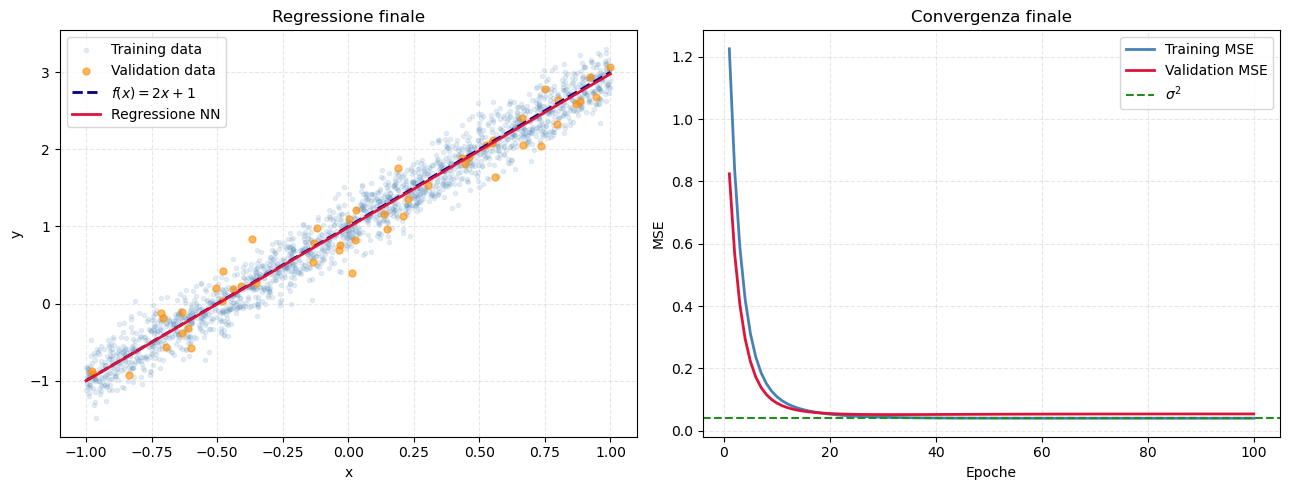

In [12]:

# ============================================================
# ESERCIZIO 11.1 - Regressione finale
# ============================================================

# Parametri selezionati
N_train_final = 2000
N_epochs_final = 100
sigma_final = 0.2

# Dataset di training selezionato
x_final = x_pool[:N_train_final]
y_final = y_pool[:N_train_final]

# Inizializzazione riproducibile
keras.utils.set_random_seed(42)

# Costruzione della rete neurale
model_final = keras.Sequential([
    keras.Input(shape=(1,)),
    keras.layers.Dense(1, activation='linear')
])

model_final.compile(
    optimizer=keras.optimizers.SGD(learning_rate=0.1),
    loss='mse'
)

# Addestramento
history_final = model_final.fit(
    x_final.reshape(-1, 1), y_final,
    epochs=N_epochs_final,
    batch_size=N_train_final,
    validation_data=(x_valid_nn, y_valid),
    shuffle=False,
    verbose=0
)

# Estrazione dei parametri appresi
weights, biases = model_final.get_weights()
w_final = float(weights[0, 0])
b_final = float(biases[0])

# Predizioni sulla griglia
y_final_pred = model_final.predict(
    x_grid.reshape(-1, 1), verbose=0
).flatten()

# MSE rispetto alla funzione teorica
mse_final_theory = np.mean((y_final_pred - y_grid)**2)

# MSE sui dati di training e validazione
mse_final_train = np.mean(
    (y_final - (w_final*x_final + b_final))**2
)

mse_final_valid = np.mean(
    (y_valid - (w_final*x_valid + b_final))**2
)

# Risultati numerici
print("REGRESSIONE FINALE")
print("-" * 45)
print(f"Training data:  {N_train_final}")
print(f"Epoche:        {N_epochs_final}")
print(f"Rumore sigma:  {sigma_final:.2f}")
print()
print(f"w = {w_final:.6f}  (teorico: 2)")
print(f"b = {b_final:.6f}  (teorico: 1)")
print()
print(f"Training MSE:  {mse_final_train:.6f}")
print(f"Validation MSE:{mse_final_valid:.6f}")
print(f"MSE teorico:   {mse_final_theory:.8f}")


# ============================================================
# Grafici della regressione finale
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Grafico 1: confronto delle funzioni
axes[0].scatter(x_final, y_final, s=9, alpha=0.12,
                color='steelblue', label='Training data')

axes[0].scatter(x_valid, y_valid, s=25, alpha=0.6,
                color='darkorange', label='Validation data')

axes[0].plot(x_grid, y_grid, '--', color='navy',
             linewidth=2, label=r'$f(x)=2x+1$')

axes[0].plot(x_grid, y_final_pred, color='crimson',
             linewidth=2, label='Regressione NN')

axes[0].set_xlabel('x')
axes[0].set_ylabel('y')
axes[0].set_title('Regressione finale')
axes[0].legend()
axes[0].grid(True, linestyle='--', alpha=0.3)

# Grafico 2: convergenza finale
epochs_final = np.arange(1, N_epochs_final + 1)

axes[1].plot(epochs_final, history_final.history['loss'],
             color='steelblue', linewidth=2,
             label='Training MSE')

axes[1].plot(epochs_final, history_final.history['val_loss'],
             color='crimson', linewidth=2,
             label='Validation MSE')

axes[1].axhline(sigma_final**2, color='forestgreen',
                linestyle='--', label=r'$\sigma^2$')

axes[1].set_xlabel('Epoche')
axes[1].set_ylabel('MSE')
axes[1].set_title('Convergenza finale')
axes[1].legend()
axes[1].grid(True, linestyle='--', alpha=0.3)

plt.tight_layout()
plt.show()



---

# Esercizio 11.2 — Regressione polinomiale con reti neurali

## Obiettivo

L'obiettivo è approssimare mediante una rete neurale artificiale la funzione polinomiale di terzo grado:

$$
f(x)=4-3x-2x^2+3x^3
$$

nell'intervallo:

$$
x\in[-1,1]
$$

A differenza dell'esercizio precedente, un singolo neurone con attivazione lineare non è sufficiente a rappresentare la funzione. È quindi necessario introdurre **hidden layer e funzioni di attivazione non lineari**.

Si analizzerà l'influenza dei principali iperparametri della rete:

- **Numero di hidden layer:** profondità della rete.
- **Numero di neuroni per layer:** capacità rappresentativa del modello.
- **Funzione di attivazione:** introduzione della non linearità.
- **Ottimizzatore:** algoritmo utilizzato per aggiornare i parametri.
- **Funzione di perdita:** criterio utilizzato per minimizzare l'errore.

## Analisi della regressione e generalizzazione

La qualità della regressione verrà valutata confrontando le predizioni della rete con la funzione teorica.

In particolare, verranno analizzati:

1. L'andamento del Training MSE e del Validation MSE durante l'addestramento.
2. La capacità di approssimare la funzione nell'intervallo utilizzato per il training.
3. La capacità di effettuare predizioni **al di fuori dell'intervallo di training**, verificando il comportamento della rete in estrapolazione.
4. La relazione tra complessità del modello, accuratezza della regressione e capacità di generalizzazione.

L'obiettivo finale è individuare un'architettura sufficientemente complessa da rappresentare il polinomio, evitando un numero eccessivo di parametri e possibili fenomeni di overfitting.


## Prima configurazione della rete neurale

Come punto di partenza, si considera una rete neurale relativamente semplice, con l'obiettivo di verificare la capacità di approssimare il polinomio prima di procedere all'ottimizzazione degli iperparametri.

### Architettura e parametri iniziali

| Parametro | Scelta iniziale |
|---|---|
| Hidden layer | 1 |
| Neuroni nell'hidden layer | 16 |
| Attivazione hidden layer | `tanh` |
| Attivazione output | `linear` |
| Ottimizzatore | Adam |
| Learning rate | 0.01 |
| Loss function | Mean Squared Error (MSE) |
| Epoche | 300 |
| Batch size | 32 |
| Training set | 500 punti |
| Validation set | 100 punti |
| Rumore gaussiano | $\sigma=0.2$ |
| Parametri addestrabili | 49 |



### Ottimizzazione successiva

Questa configurazione costituisce un **modello di riferimento (baseline)** e non rappresenta necessariamente la soluzione ottimale.

Si procederà quindi confrontando differenti numeri di layer, neuroni, funzioni di attivazione, ottimizzatori e funzioni di perdita, mantenendo condizioni di confronto il più possibile omogenee.

La configurazione finale verrà selezionata considerando l'accuratezza sul validation set, la complessità della rete e la stabilità dell'addestramento.


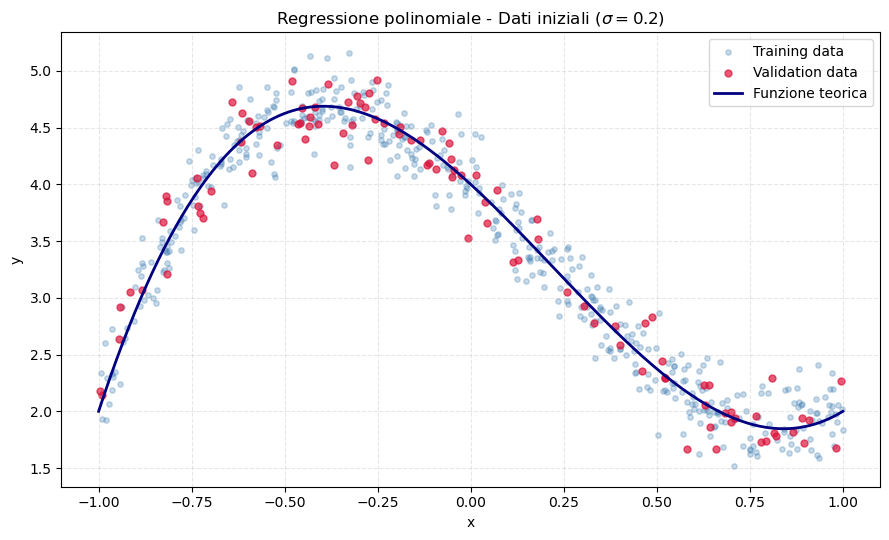

In [14]:

# ============================================================
# ESERCIZIO 11.2 - Regressione polinomiale
# ============================================================

# Funzione teorica
def f_poly(x):
    return 4 - 3*x - 2*x**2 + 3*x**3

# Parametri della simulazione
N_train_poly = 500
N_valid_poly = 100
sigma_poly = 0.2

rng_poly = np.random.default_rng(112)

# Generazione degli input
x_train_poly = rng_poly.uniform(-1, 1, N_train_poly)
x_valid_poly = rng_poly.uniform(-1, 1, N_valid_poly)

# Aggiunta del rumore gaussiano
y_train_poly = f_poly(x_train_poly) + rng_poly.normal(
    0, sigma_poly, N_train_poly
)

y_valid_poly = f_poly(x_valid_poly) + rng_poly.normal(
    0, sigma_poly, N_valid_poly
)

# Funzione teorica su una griglia regolare
x_plot_poly = np.linspace(-1, 1, 500)
y_plot_poly = f_poly(x_plot_poly)

# Visualizzazione
plt.figure(figsize=(9, 5.5))

plt.scatter(x_train_poly, y_train_poly, s=15,
            color='steelblue', alpha=0.3, label='Training data')

plt.scatter(x_valid_poly, y_valid_poly, s=25,
            color='crimson', alpha=0.7, label='Validation data')

plt.plot(x_plot_poly, y_plot_poly, color='navy',
         linewidth=2, label='Funzione teorica')

plt.xlabel('x')
plt.ylabel('y')
plt.title(r'Regressione polinomiale - Dati iniziali ($\sigma=0.2$)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.3)
plt.tight_layout()
plt.show()


In [15]:

# ============================================================
# Costruzione della rete neurale - Modello iniziale
# ============================================================

# Parametri del modello
N_neurons_poly = 16
learning_rate_poly = 0.01

# Inizializzazione riproducibile
keras.utils.set_random_seed(42)

# Costruzione della rete neurale
model_poly = keras.Sequential([
    keras.Input(shape=(1,)),
    keras.layers.Dense(N_neurons_poly, activation='tanh'),
    keras.layers.Dense(1, activation='linear')
])

# Compilazione del modello
model_poly.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=learning_rate_poly
    ),
    loss='mse',
    metrics=['mse']
)

# Visualizzazione dell'architettura
model_poly.summary()


Model: "sequential_25"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense_25 (Dense)                     │ (None, 16)                  │              32 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_26 (Dense)                     │ (None, 1)                   │              17 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 49 (196.00 B)

 Trainable params: 49 (196.00 B)

 Non-trainable params: 0 (0.00 B)

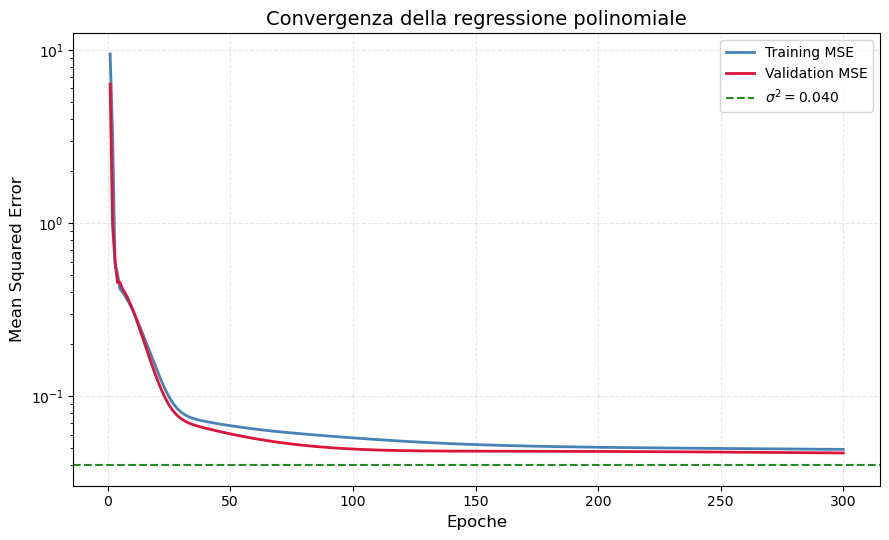

Training MSE:   0.049336
Validation MSE: 0.047046
Varianza rumore: 0.040000


In [16]:

# ============================================================
# Addestramento della rete neurale - Esercizio 11.2
# ============================================================

# Parametri dell'addestramento
N_epochs_poly = 300
batch_size_poly = 32

# Preparazione degli input per Keras
x_train_poly_nn = x_train_poly.reshape(-1, 1)
x_valid_poly_nn = x_valid_poly.reshape(-1, 1)

# Addestramento
history_poly = model_poly.fit(
    x_train_poly_nn, y_train_poly,
    epochs=N_epochs_poly,
    batch_size=batch_size_poly,
    validation_data=(x_valid_poly_nn, y_valid_poly),
    shuffle=True,
    verbose=0
)

# Estrazione degli errori
train_loss_poly = history_poly.history['loss']
valid_loss_poly = history_poly.history['val_loss']

epochs_poly = np.arange(1, N_epochs_poly + 1)

# Grafico della convergenza
plt.figure(figsize=(9, 5.5))

plt.plot(epochs_poly, train_loss_poly,
         color='steelblue', linewidth=2, label='Training MSE')

plt.plot(epochs_poly, valid_loss_poly,
         color='crimson', linewidth=2, label='Validation MSE')

plt.axhline(sigma_poly**2, color='forestgreen',
            linestyle='--', linewidth=1.5,
            label=fr'$\sigma^2={sigma_poly**2:.3f}$')

plt.xlabel('Epoche', fontsize=12)
plt.ylabel('Mean Squared Error', fontsize=12)
plt.title('Convergenza della regressione polinomiale', fontsize=14)

plt.yscale('log')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.3)
plt.tight_layout()
plt.show()

# Risultati finali
print(f"Training MSE:   {train_loss_poly[-1]:.6f}")
print(f"Validation MSE: {valid_loss_poly[-1]:.6f}")
print(f"Varianza rumore: {sigma_poly**2:.6f}")






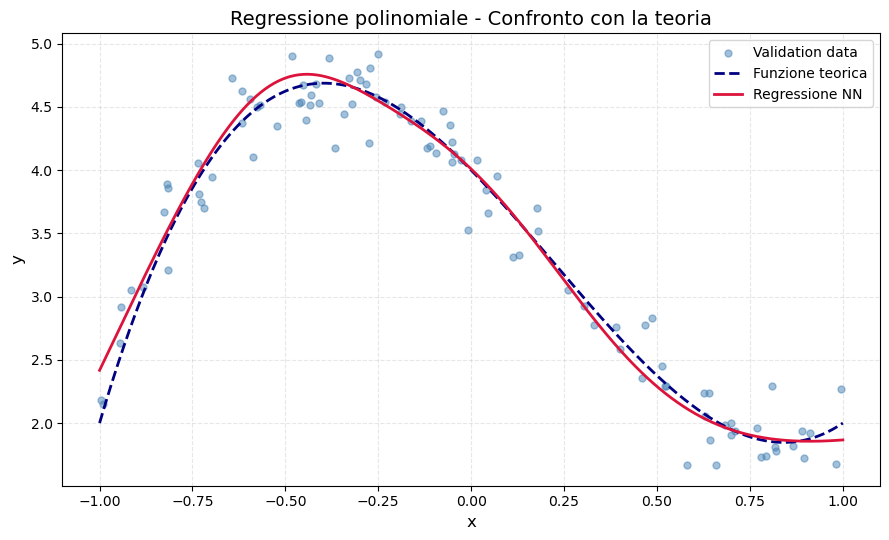

Training MSE:  0.049336
Validation MSE: 0.047046
MSE rispetto alla funzione esatta: 0.007067


In [17]:

# ============================================================
# Confronto tra funzione teorica e regressione neurale
# ============================================================

# Predizioni della rete nell'intervallo [-1, 1]
y_pred_poly = model_poly.predict(
    x_plot_poly.reshape(-1, 1), verbose=0
).flatten()

# MSE rispetto alla funzione teorica
mse_theory_poly = np.mean((y_plot_poly - y_pred_poly)**2)

# Creazione del grafico
plt.figure(figsize=(9, 5.5))

# Dati di validazione
plt.scatter(x_valid_poly, y_valid_poly,
            color='steelblue', s=25, alpha=0.5,
            label='Validation data')

# Funzione teorica
plt.plot(x_plot_poly, y_plot_poly,
         color='navy', linestyle='--', linewidth=2,
         label='Funzione teorica')

# Regressione della rete neurale
plt.plot(x_plot_poly, y_pred_poly,
         color='crimson', linewidth=2,
         label='Regressione NN')

# Personalizzazione
plt.xlabel('x', fontsize=12)
plt.ylabel('y', fontsize=12)
plt.title('Regressione polinomiale - Confronto con la teoria',
          fontsize=14)

plt.legend(fontsize=10)
plt.grid(True, linestyle='--', alpha=0.3)
plt.tight_layout()
plt.show()

# Risultati numerici
print(f"Training MSE:  {train_loss_poly[-1]:.6f}")
print(f"Validation MSE: {valid_loss_poly[-1]:.6f}")
print(f"MSE rispetto alla funzione esatta: {mse_theory_poly:.6f}")


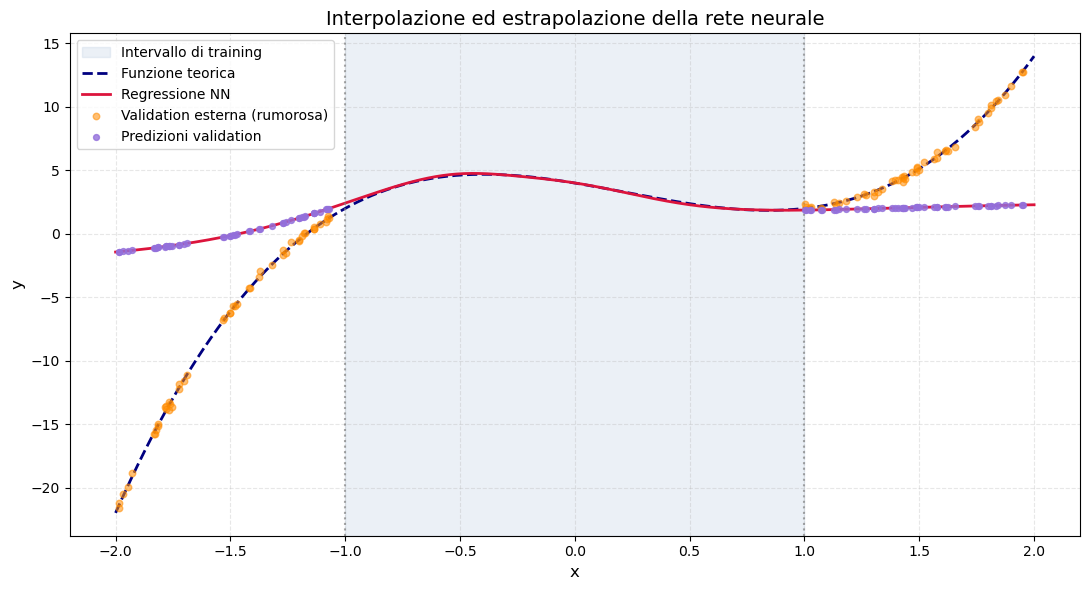

ERRORI SULLA GRIGLIA REGOLARE
MSE interpolazione: 0.006975
MSE estrapolazione: 59.614362

VALIDATION SET ESTERNO
Numero di punti: 100
MSE rispetto alla funzione esatta: 58.763330
RMSE rispetto alla funzione esatta: 7.665724
MAE rispetto alla funzione esatta: 5.614567
MSE rispetto ai dati rumorosi:    58.715557


In [29]:

# ============================================================
# Studio dell'estrapolazione - Esercizio 11.2
# ============================================================

# Intervallo esteso
x_ext = np.linspace(-2, 2, 1000)

# Funzione teorica e predizione della rete
y_ext_true = f_poly(x_ext)

y_ext_pred = model_poly.predict(
    x_ext.reshape(-1, 1), verbose=0
).flatten()

# Separazione tra interpolazione ed estrapolazione
mask_in = np.abs(x_ext) <= 1
mask_out = np.abs(x_ext) > 1

# MSE sulla griglia regolare
mse_in = np.mean(
    (y_ext_true[mask_in] - y_ext_pred[mask_in])**2
)

mse_out = np.mean(
    (y_ext_true[mask_out] - y_ext_pred[mask_out])**2
)


# ============================================================
# Generazione di un validation set esterno
# ============================================================

rng_ext = np.random.default_rng(123)

N_valid_ext = 100

# Punti distribuiti nei due intervalli esterni
x_valid_ext = np.concatenate([
    rng_ext.uniform(-2, -1, N_valid_ext // 2),
    rng_ext.uniform(1, 2, N_valid_ext // 2)
])

x_valid_ext.sort()

# Valori teorici esatti
y_valid_ext_true = f_poly(x_valid_ext)

# Valori di validazione con rumore gaussiano
y_valid_ext = y_valid_ext_true + rng_ext.normal(
    0, sigma_poly, N_valid_ext
)

# Predizioni della rete sui nuovi punti
y_valid_ext_pred = model_poly.predict(
    x_valid_ext.reshape(-1, 1), verbose=0
).flatten()


# ============================================================
# Calcolo degli errori sui nuovi punti
# ============================================================

# Scostamento delle predizioni dalla funzione esatta
residuals_ext = y_valid_ext_pred - y_valid_ext_true

mse_valid_ext = np.mean(residuals_ext**2)
rmse_valid_ext = np.sqrt(mse_valid_ext)
mae_valid_ext = np.mean(np.abs(residuals_ext))

# MSE rispetto alle osservazioni rumorose
mse_valid_ext_noisy = np.mean(
    (y_valid_ext_pred - y_valid_ext)**2
)


# ============================================================
# Visualizzazione
# ============================================================

plt.figure(figsize=(11, 6))

# Intervallo utilizzato durante il training
plt.axvspan(-1, 1, color='lightsteelblue', alpha=0.25,
            label='Intervallo di training')

# Funzione teorica
plt.plot(x_ext, y_ext_true, '--',
         color='navy', linewidth=2,
         label='Funzione teorica')

# Regressione della rete neurale
plt.plot(x_ext, y_ext_pred,
         color='crimson', linewidth=2,
         label='Regressione NN')

# Nuovi dati di validazione esterna
plt.scatter(x_valid_ext, y_valid_ext,
            color='darkorange', s=22, alpha=0.55,
            label='Validation esterna (rumorosa)', zorder=3)

# Predizioni nei punti di validazione
plt.scatter(x_valid_ext, y_valid_ext_pred,
            color='mediumpurple', s=18, alpha=0.8,
            label='Predizioni validation', zorder=4)

# Limiti del training
plt.axvline(-1, color='gray', linestyle=':', alpha=0.7)
plt.axvline(1, color='gray', linestyle=':', alpha=0.7)

plt.xlabel('x', fontsize=12)
plt.ylabel('y', fontsize=12)
plt.title('Interpolazione ed estrapolazione della rete neurale',
          fontsize=14)

plt.legend()
plt.grid(True, linestyle='--', alpha=0.3)
plt.tight_layout()
plt.show()


# ============================================================
# Risultati numerici
# ============================================================

print("ERRORI SULLA GRIGLIA REGOLARE")
print(f"MSE interpolazione: {mse_in:.6f}")
print(f"MSE estrapolazione: {mse_out:.6f}")

print("\nVALIDATION SET ESTERNO")
print(f"Numero di punti: {N_valid_ext}")
print(f"MSE rispetto alla funzione esatta: {mse_valid_ext:.6f}")
print(f"RMSE rispetto alla funzione esatta: {rmse_valid_ext:.6f}")
print(f"MAE rispetto alla funzione esatta: {mae_valid_ext:.6f}")
print(f"MSE rispetto ai dati rumorosi:    {mse_valid_ext_noisy:.6f}")


## Studio della dipemndenza dalla funzione di attivazione

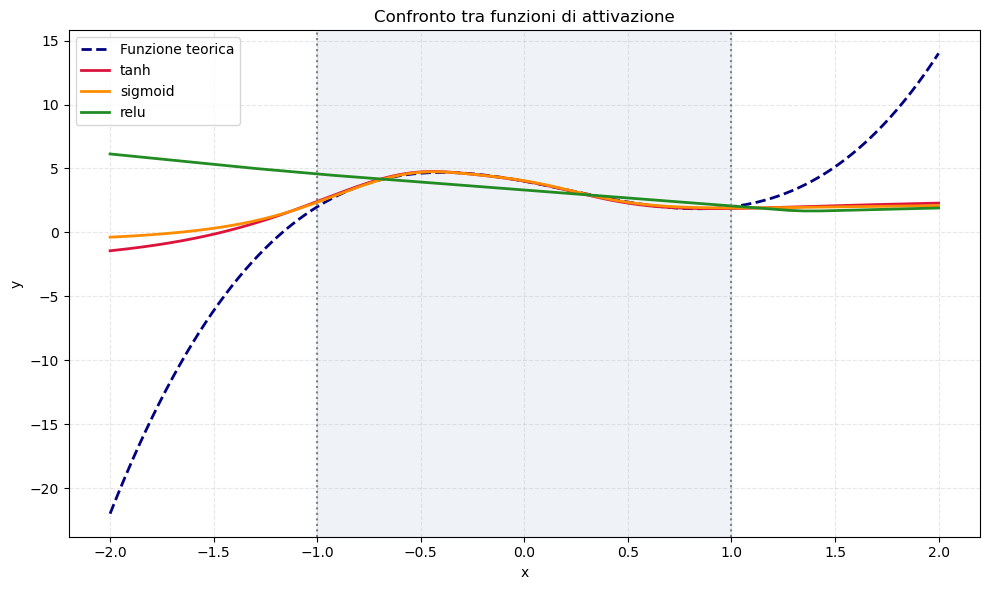

Attivazione     Train MSE    Valid MSE    MSE interno    MSE esterno
----------------------------------------------------------------------
tanh             0.049336     0.047046       0.006975      59.614362
sigmoid          0.043488     0.046904       0.004235      65.990823
relu             0.541869     0.599636       0.565469     124.531148


In [19]:

# ============================================================
# Confronto tra funzioni di attivazione
# ============================================================

activations_poly = ['tanh', 'sigmoid', 'relu']
colors_poly = ['crimson', 'darkorange', 'forestgreen']

results_activation = {}

plt.figure(figsize=(10, 6))

# Funzione teorica
plt.plot(x_ext, y_ext_true, '--', color='navy',
         linewidth=2, label='Funzione teorica')

for activation, color in zip(activations_poly, colors_poly):

    # Stessa inizializzazione casuale
    keras.utils.set_random_seed(42)

    # Rete con un hidden layer di 16 neuroni
    model_act = keras.Sequential([
        keras.Input(shape=(1,)),
        keras.layers.Dense(16, activation=activation),
        keras.layers.Dense(1, activation='linear')
    ])

    model_act.compile(
        optimizer=keras.optimizers.Adam(learning_rate=0.01),
        loss='mse'
    )

    # Addestramento
    history_act = model_act.fit(
        x_train_poly_nn, y_train_poly,
        epochs=300,
        batch_size=32,
        validation_data=(x_valid_poly_nn, y_valid_poly),
        shuffle=True,
        verbose=0
    )

    # Predizioni sull'intervallo esteso
    y_act = model_act.predict(
        x_ext.reshape(-1, 1), verbose=0
    ).flatten()

    # Errori di interpolazione ed estrapolazione
    mse_act_in = np.mean((y_ext_true[mask_in] -
                          y_act[mask_in])**2)

    mse_act_out = np.mean((y_ext_true[mask_out] -
                           y_act[mask_out])**2)

    results_activation[activation] = {
        'train': history_act.history['loss'][-1],
        'valid': history_act.history['val_loss'][-1],
        'interpolation': mse_act_in,
        'extrapolation': mse_act_out
    }

    plt.plot(x_ext, y_act, color=color,
             linewidth=2, label=activation)

# Intervallo di training
plt.axvspan(-1, 1, color='lightsteelblue', alpha=0.2)
plt.axvline(-1, color='gray', linestyle=':')
plt.axvline(1, color='gray', linestyle=':')

plt.xlabel('x')
plt.ylabel('y')
plt.title('Confronto tra funzioni di attivazione')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.3)
plt.tight_layout()
plt.show()

# Tabella riassuntiva
print(f"{'Attivazione':<12} {'Train MSE':>12} {'Valid MSE':>12} "
      f"{'MSE interno':>14} {'MSE esterno':>14}")
print("-" * 70)

for activation, values in results_activation.items():
    print(f"{activation:<12} "
          f"{values['train']:12.6f} "
          f"{values['valid']:12.6f} "
          f"{values['interpolation']:14.6f} "
          f"{values['extrapolation']:14.6f}")


## Studio della dipendenza dall'architettura della rete (layer e neuroni per layer)

Layers  Neurons   Params    Train MSE    Valid MSE     MSE f(x)
-------------------------------------------------------------------
     1        8       25     0.045428     0.045114     0.003516
     1       16       49     0.049336     0.047046     0.007067
     1       32       97     0.053935     0.051985     0.014342
     2        8       97     0.044721     0.042719     0.004369
     2       16      321     0.046542     0.043468     0.006719
     2       32     1153     0.048552     0.048409     0.011430
     3        8      169     0.045474     0.044584     0.007612
     3       16      593     0.049830     0.047719     0.014009
     3       32     2209     0.043878     0.050016     0.008803


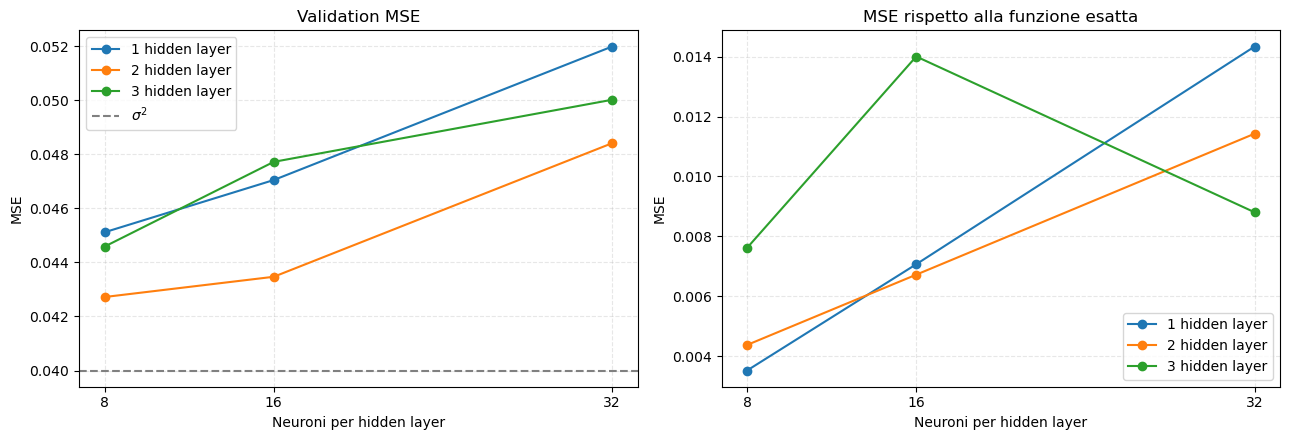


Migliore architettura per Validation MSE:
Hidden layer: 2
Neuroni per layer: 8
Parametri addestrabili: 97
Validation MSE: 0.042719


In [20]:

# ============================================================
# Studio dell'architettura della rete neurale
# ============================================================

layers_values = [1, 2, 3]
neurons_values = [8, 16, 32]

results_arch = []

for n_layers in layers_values:
    for n_neurons in neurons_values:

        # Inizializzazione riproducibile
        keras.utils.set_random_seed(42)

        # Costruzione della rete
        model_arch = keras.Sequential([
            keras.Input(shape=(1,))
        ])

        for _ in range(n_layers):
            model_arch.add(
                keras.layers.Dense(n_neurons, activation='tanh')
            )

        model_arch.add(
            keras.layers.Dense(1, activation='linear')
        )

        model_arch.compile(
            optimizer=keras.optimizers.Adam(learning_rate=0.01),
            loss='mse'
        )

        # Addestramento
        history_arch = model_arch.fit(
            x_train_poly_nn, y_train_poly,
            epochs=300,
            batch_size=32,
            validation_data=(x_valid_poly_nn, y_valid_poly),
            shuffle=True,
            verbose=0
        )

        # Predizione sulla funzione esatta
        y_arch_pred = model_arch.predict(
            x_plot_poly.reshape(-1, 1), verbose=0
        ).flatten()

        mse_exact = np.mean(
            (y_plot_poly - y_arch_pred)**2
        )

        # Salvataggio dei risultati
        results_arch.append({
            'layers': n_layers,
            'neurons': n_neurons,
            'params': model_arch.count_params(),
            'train': history_arch.history['loss'][-1],
            'valid': history_arch.history['val_loss'][-1],
            'exact': mse_exact
        })

# ============================================================
# Tabella riassuntiva
# ============================================================

print(f"{'Layers':>6} {'Neurons':>8} {'Params':>8} "
      f"{'Train MSE':>12} {'Valid MSE':>12} {'MSE f(x)':>12}")
print("-" * 67)

for r in results_arch:
    print(f"{r['layers']:6d} {r['neurons']:8d} "
          f"{r['params']:8d} {r['train']:12.6f} "
          f"{r['valid']:12.6f} {r['exact']:12.6f}")

# ============================================================
# Confronto grafico
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

for n_layers in layers_values:

    subset = [r for r in results_arch
              if r['layers'] == n_layers]

    neurons = [r['neurons'] for r in subset]
    mse_valid = [r['valid'] for r in subset]
    mse_exact = [r['exact'] for r in subset]

    axes[0].plot(neurons, mse_valid, 'o-',
                 label=f'{n_layers} hidden layer')

    axes[1].plot(neurons, mse_exact, 'o-',
                 label=f'{n_layers} hidden layer')

axes[0].axhline(sigma_poly**2, linestyle='--',
                color='gray', label=r'$\sigma^2$')

axes[0].set_title('Validation MSE')
axes[1].set_title('MSE rispetto alla funzione esatta')

for ax in axes:
    ax.set_xlabel('Neuroni per hidden layer')
    ax.set_ylabel('MSE')
    ax.set_xticks(neurons_values)
    ax.legend()
    ax.grid(True, linestyle='--', alpha=0.3)

plt.tight_layout()
plt.show()

# Architettura con il minore Validation MSE
best_arch = min(results_arch, key=lambda r: r['valid'])

print("\nMigliore architettura per Validation MSE:")
print(f"Hidden layer: {best_arch['layers']}")
print(f"Neuroni per layer: {best_arch['neurons']}")
print(f"Parametri addestrabili: {best_arch['params']}")
print(f"Validation MSE: {best_arch['valid']:.6f}")


## Dipendenza dagli ottimizzatori

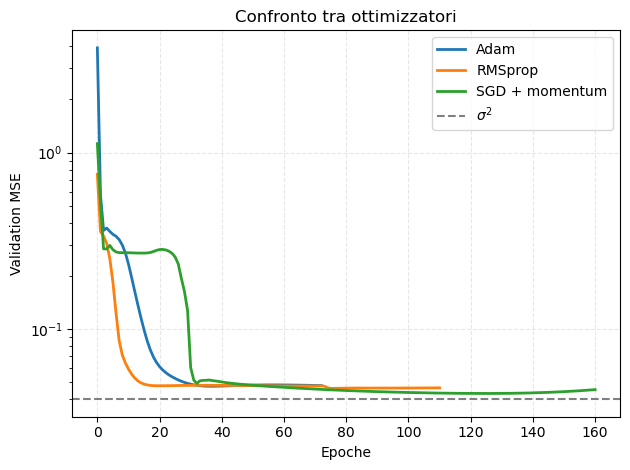

Optimizer         Epoche    Train MSE    Valid MSE     MSE f(x)
-----------------------------------------------------------------
Adam                  73     0.045442     0.047335     0.008808
RMSprop              111     0.040701     0.046003     0.001282
SGD + momentum       161     0.042637     0.043083     0.004461

Miglior ottimizzatore: SGD + momentum
Validation MSE: 0.043083


In [21]:

# ============================================================
# Confronto tra ottimizzatori - Esercizio 11.2
# ============================================================

# Configurazioni degli ottimizzatori
optimizers_poly = {
    'Adam': lambda: keras.optimizers.Adam(learning_rate=0.01),
    'RMSprop': lambda: keras.optimizers.RMSprop(learning_rate=0.01),
    'SGD + momentum': lambda: keras.optimizers.SGD(
        learning_rate=0.05, momentum=0.9
    )
}

results_opt = []
models_opt = {}

for name, optimizer_fn in optimizers_poly.items():

    keras.utils.set_random_seed(42)

    # Architettura: 2 hidden layer da 8 neuroni
    model_opt = keras.Sequential([
        keras.Input(shape=(1,)),
        keras.layers.Dense(8, activation='tanh'),
        keras.layers.Dense(8, activation='tanh'),
        keras.layers.Dense(1, activation='linear')
    ])

    model_opt.compile(
        optimizer=optimizer_fn(),
        loss='mse'
    )

    # Interruzione quando il Validation MSE non migliora
    early_stop = keras.callbacks.EarlyStopping(
        monitor='val_loss',
        patience=35,
        restore_best_weights=True
    )

    history_opt = model_opt.fit(
        x_train_poly_nn, y_train_poly,
        epochs=250,
        batch_size=32,
        validation_data=(x_valid_poly_nn, y_valid_poly),
        callbacks=[early_stop],
        shuffle=True,
        verbose=0
    )

    # Valutazione del modello con i migliori pesi
    train_mse = model_opt.evaluate(
        x_train_poly_nn, y_train_poly, verbose=0
    )

    valid_mse = model_opt.evaluate(
        x_valid_poly_nn, y_valid_poly, verbose=0
    )

    y_pred = model_opt.predict(
        x_plot_poly.reshape(-1, 1), verbose=0
    ).flatten()

    mse_exact = np.mean((y_plot_poly - y_pred)**2)

    results_opt.append({
        'name': name,
        'train': train_mse,
        'valid': valid_mse,
        'exact': mse_exact,
        'epochs': len(history_opt.history['loss'])
    })

    models_opt[name] = model_opt

    # Curve di convergenza
    plt.plot(
        history_opt.history['val_loss'],
        linewidth=2, label=name
    )

# ============================================================
# Grafico della convergenza
# ============================================================

plt.axhline(sigma_poly**2, color='gray',
            linestyle='--', label=r'$\sigma^2$')

plt.xlabel('Epoche')
plt.ylabel('Validation MSE')
plt.title('Confronto tra ottimizzatori')
plt.yscale('log')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.3)
plt.tight_layout()
plt.show()

# ============================================================
# Tabella dei risultati
# ============================================================

print(f"{'Optimizer':<16} {'Epoche':>7} "
      f"{'Train MSE':>12} {'Valid MSE':>12} {'MSE f(x)':>12}")
print("-" * 65)

for r in results_opt:
    print(f"{r['name']:<16} {r['epochs']:7d} "
          f"{r['train']:12.6f} {r['valid']:12.6f} "
          f"{r['exact']:12.6f}")

# Selezione dell'ottimizzatore
best_opt = min(results_opt, key=lambda r: r['valid'])

print(f"\nMiglior ottimizzatore: {best_opt['name']}")
print(f"Validation MSE: {best_opt['valid']:.6f}")


## Dipendenza dalla loss function

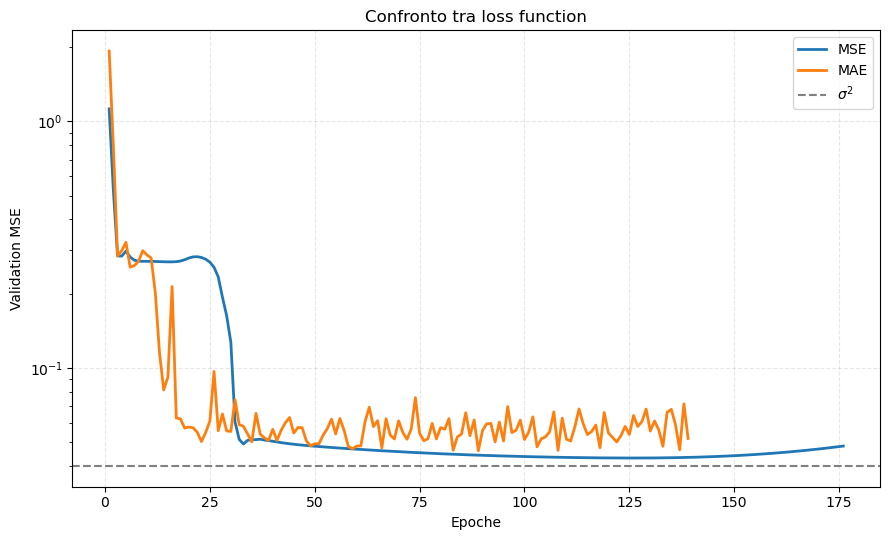

Loss       Epoche    Train MSE    Valid MSE     MSE f(x)
---------------------------------------------------------
MSE           176     0.042637     0.043083     0.004461
MAE           139     0.044819     0.046116     0.006298

Migliore loss per Validation MSE: MSE


In [22]:

# ============================================================
# Confronto tra loss function: MSE e MAE
# ============================================================

loss_functions = {
    'MSE': 'mse',
    'MAE': 'mae'
}

results_loss = []
models_loss = {}

plt.figure(figsize=(9, 5.5))

for loss_name, loss_fn in loss_functions.items():

    keras.utils.set_random_seed(42)

    # Architettura selezionata: 2 hidden layer da 8 neuroni
    model_loss = keras.Sequential([
        keras.Input(shape=(1,)),
        keras.layers.Dense(8, activation='tanh'),
        keras.layers.Dense(8, activation='tanh'),
        keras.layers.Dense(1, activation='linear')
    ])

    model_loss.compile(
        optimizer=keras.optimizers.SGD(
            learning_rate=0.05, momentum=0.9
        ),
        loss=loss_fn,
        metrics=[keras.metrics.MeanSquaredError(name='mse')]
    )

    # Early Stopping sullo stesso criterio per entrambi
    early_stop = keras.callbacks.EarlyStopping(
        monitor='val_mse',
        patience=50,
        restore_best_weights=True
    )

    history_loss = model_loss.fit(
        x_train_poly_nn, y_train_poly,
        epochs=250,
        batch_size=32,
        validation_data=(x_valid_poly_nn, y_valid_poly),
        callbacks=[early_stop],
        shuffle=True,
        verbose=0
    )

    # Valutazione tramite MSE
    train_mse = model_loss.evaluate(
        x_train_poly_nn, y_train_poly,
        verbose=0, return_dict=True
    )['mse']

    valid_mse = model_loss.evaluate(
        x_valid_poly_nn, y_valid_poly,
        verbose=0, return_dict=True
    )['mse']

    # Errore rispetto alla funzione esatta
    y_pred_loss = model_loss.predict(
        x_plot_poly.reshape(-1, 1), verbose=0
    ).flatten()

    mse_exact = np.mean((y_plot_poly - y_pred_loss)**2)

    results_loss.append({
        'loss': loss_name,
        'train': train_mse,
        'valid': valid_mse,
        'exact': mse_exact,
        'epochs': len(history_loss.history['loss'])
    })

    models_loss[loss_name] = model_loss

    # Confronto della convergenza
    plt.plot(
        np.arange(1, len(history_loss.history['val_mse']) + 1),
        history_loss.history['val_mse'],
        linewidth=2,
        label=loss_name
    )

plt.axhline(sigma_poly**2, color='gray',
            linestyle='--', label=r'$\sigma^2$')

plt.xlabel('Epoche')
plt.ylabel('Validation MSE')
plt.title('Confronto tra loss function')
plt.yscale('log')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.3)
plt.tight_layout()
plt.show()

# ============================================================
# Tabella dei risultati
# ============================================================

print(f"{'Loss':<8} {'Epoche':>8} {'Train MSE':>12} "
      f"{'Valid MSE':>12} {'MSE f(x)':>12}")
print("-" * 57)

for r in results_loss:
    print(f"{r['loss']:<8} {r['epochs']:8d} "
          f"{r['train']:12.6f} {r['valid']:12.6f} "
          f"{r['exact']:12.6f}")

best_loss = min(results_loss, key=lambda r: r['valid'])

print(f"\nMigliore loss per Validation MSE: {best_loss['loss']}")


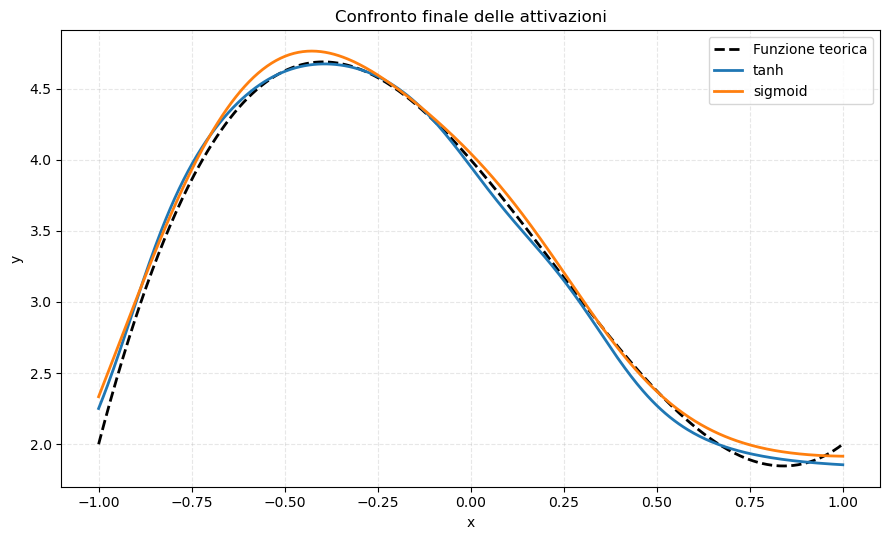

Activation      Train MSE    Valid MSE     MSE f(x)
---------------------------------------------------
tanh             0.042637     0.043083     0.004461
sigmoid          0.043918     0.048572     0.006424

Migliore attivazione: tanh


In [23]:

# ============================================================
# Confronto finale delle attivazioni: tanh vs sigmoid
# ============================================================

# Modello tanh già addestrato nella cella precedente
model_tanh_final = models_loss['MSE']

# Costruzione della rete sigmoid
keras.utils.set_random_seed(42)

model_sigmoid_final = keras.Sequential([
    keras.Input(shape=(1,)),
    keras.layers.Dense(8, activation='sigmoid'),
    keras.layers.Dense(8, activation='sigmoid'),
    keras.layers.Dense(1, activation='linear')
])

model_sigmoid_final.compile(
    optimizer=keras.optimizers.SGD(
        learning_rate=0.05, momentum=0.9
    ),
    loss='mse',
    metrics=[keras.metrics.MeanSquaredError(name='mse')]
)

# Early Stopping
early_stop = keras.callbacks.EarlyStopping(
    monitor='val_mse',
    patience=50,
    restore_best_weights=True
)

history_sigmoid_final = model_sigmoid_final.fit(
    x_train_poly_nn, y_train_poly,
    epochs=250,
    batch_size=32,
    validation_data=(x_valid_poly_nn, y_valid_poly),
    callbacks=[early_stop],
    shuffle=True,
    verbose=0
)

# ============================================================
# Valutazione dei due modelli
# ============================================================

final_activation_models = {
    'tanh': model_tanh_final,
    'sigmoid': model_sigmoid_final
}

results_activation_final = {}

plt.figure(figsize=(9, 5.5))

plt.plot(x_plot_poly, y_plot_poly, 'k--',
         linewidth=2, label='Funzione teorica')

for name, model in final_activation_models.items():

    train_mse = model.evaluate(
        x_train_poly_nn, y_train_poly, verbose=0
    )[1]

    valid_mse = model.evaluate(
        x_valid_poly_nn, y_valid_poly, verbose=0
    )[1]

    y_pred = model.predict(
        x_plot_poly.reshape(-1, 1), verbose=0
    ).flatten()

    mse_exact = np.mean((y_plot_poly - y_pred)**2)

    results_activation_final[name] = {
        'train': train_mse,
        'valid': valid_mse,
        'exact': mse_exact
    }

    plt.plot(x_plot_poly, y_pred, linewidth=2, label=name)

plt.xlabel('x')
plt.ylabel('y')
plt.title('Confronto finale delle attivazioni')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.3)
plt.tight_layout()
plt.show()

# Tabella riassuntiva
print(f"{'Activation':<12} {'Train MSE':>12} "
      f"{'Valid MSE':>12} {'MSE f(x)':>12}")
print("-" * 51)

for name, r in results_activation_final.items():
    print(f"{name:<12} {r['train']:12.6f} "
          f"{r['valid']:12.6f} {r['exact']:12.6f}")

best_activation_final = min(
    results_activation_final,
    key=lambda name: results_activation_final[name]['valid']
)

print(f"\nMigliore attivazione: {best_activation_final}")


## Architettura finale selezionata

Dopo il confronto tra diverse configurazioni, viene selezionata come architettura finale la seguente rete neurale:

| Componente | Scelta finale |
|---|---|
| Input | 1 variabile |
| Hidden layer | 2 |
| Neuroni per hidden layer | 8 + 8 |
| Attivazione hidden layer | `tanh` |
| Output layer | 1 neurone con attivazione `linear` |
| Ottimizzatore | `SGD` con momentum |
| Learning rate | 0.05 |
| Momentum | 0.9 |
| Loss function | `MSE` |
| Criterio di arresto | Early Stopping su `val_mse` |
| Patience | 50 |

### Motivazione della scelta

La configurazione scelta rappresenta un buon compromesso tra complessità e accuratezza:

- **2 hidden layer da 8 neuroni** hanno fornito il miglior Validation MSE tra le architetture testate.
- **L'attivazione `tanh`** è risultata migliore della `sigmoid` nel confronto finale con la stessa architettura.
- **SGD con momentum** ha mostrato la migliore capacità di generalizzazione nel confronto tra ottimizzatori.
- **La loss MSE** è risultata più adatta della MAE, in accordo con la presenza di rumore gaussiano nei dati.
- **L'Early Stopping** consente di interrompere l'addestramento quando il validation error non migliora più, evitando epoche inutili e limitando il rischio di overfitting.

Questa rete verrà quindi utilizzata come modello finale per la regressione polinomiale.

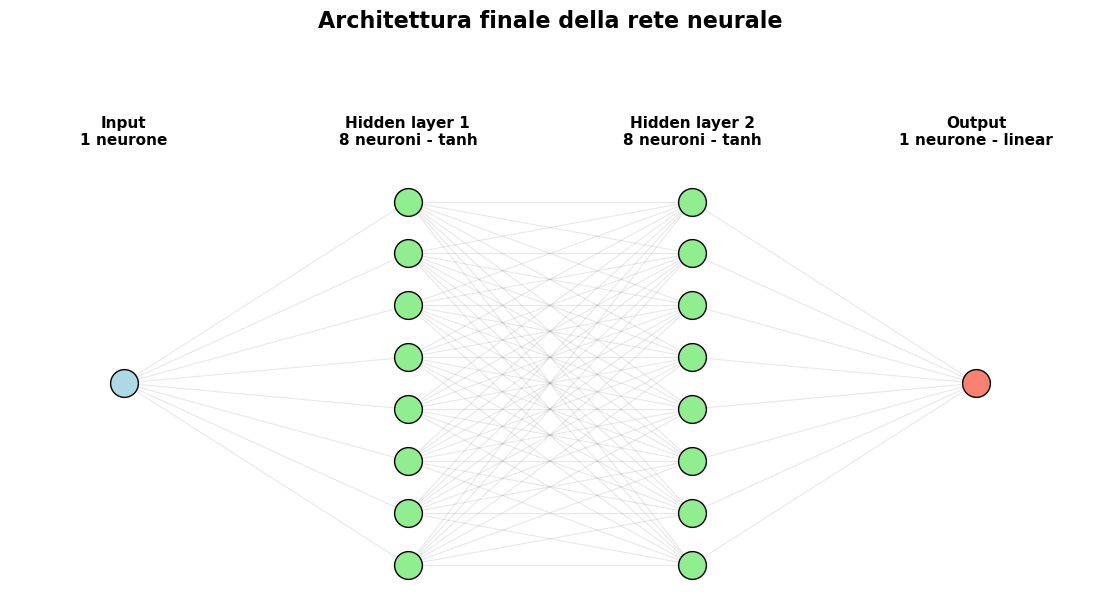

In [27]:

# ============================================================
# Schema grafico dell'architettura finale
# ============================================================

import matplotlib.pyplot as plt
import numpy as np

fig, ax = plt.subplots(figsize=(12, 6.5))

# Posizione orizzontale dei layer
x_layers = [0, 1.5, 3.0, 4.5]

# Posizione verticale dei neuroni
y_input = [3.5]
y_hidden = np.linspace(0, 7, 8)
y_output = [3.5]

layers_y = [y_input, y_hidden, y_hidden, y_output]

# Disegno delle connessioni
for i in range(len(x_layers) - 1):
    for y1 in layers_y[i]:
        for y2 in layers_y[i + 1]:
            ax.plot(
                [x_layers[i], x_layers[i + 1]],
                [y1, y2],
                color='gray',
                alpha=0.18,
                linewidth=0.8,
                zorder=1
            )

# Disegno dei neuroni
colors = ['lightblue', 'lightgreen', 'lightgreen', 'salmon']

for x, y_values, color in zip(x_layers, layers_y, colors):
    ax.scatter(
        [x] * len(y_values),
        y_values,
        s=400,
        color=color,
        edgecolors='black',
        linewidths=1,
        zorder=3
    )

# Etichette dei layer
labels = [
    'Input\n1 neurone',
    'Hidden layer 1\n8 neuroni - tanh',
    'Hidden layer 2\n8 neuroni - tanh',
    'Output\n1 neurone - linear'
]

for x, label in zip(x_layers, labels):
    ax.text(
        x, 8.35, label,
        ha='center',
        va='center',
        fontsize=11,
        fontweight='bold'
    )

# Titolo separato dalle etichette
fig.suptitle(
    'Architettura finale della rete neurale',
    fontsize=16,
    fontweight='bold',
    y=0.97
)

# Impostazioni grafiche
ax.set_xlim(-0.6, 5.1)
ax.set_ylim(-0.7, 9.2)
ax.axis('off')

# Spazio dedicato al titolo
fig.subplots_adjust(
    left=0.05,
    right=0.95,
    bottom=0.06,
    top=0.85
)

plt.show()


In [25]:
# ============================================================
# Modello finale - Esercizio 11.2
# ============================================================

keras.utils.set_random_seed(42)

model_poly_final = keras.Sequential([
    keras.Input(shape=(1,)),
    keras.layers.Dense(8, activation='tanh'),
    keras.layers.Dense(8, activation='tanh'),
    keras.layers.Dense(1, activation='linear')
])

model_poly_final.compile(
    optimizer=keras.optimizers.SGD(
        learning_rate=0.05,
        momentum=0.9
    ),
    loss='mse',
    metrics=[keras.metrics.MeanSquaredError(name='mse')]
)

early_stop_final = keras.callbacks.EarlyStopping(
    monitor='val_mse',
    patience=50,
    restore_best_weights=True
)

history_poly_final = model_poly_final.fit(
    x_train_poly_nn, y_train_poly,
    epochs=250,
    batch_size=32,
    validation_data=(x_valid_poly_nn, y_valid_poly),
    shuffle=True,
    callbacks=[early_stop_final],
    verbose=0
)

RISULTATI FINALI - ESERCIZIO 11.2
---------------------------------------------
Epoche effettive: 176
Training MSE:     0.042637
Validation MSE:   0.043083
MSE rispetto a f(x): 0.004461


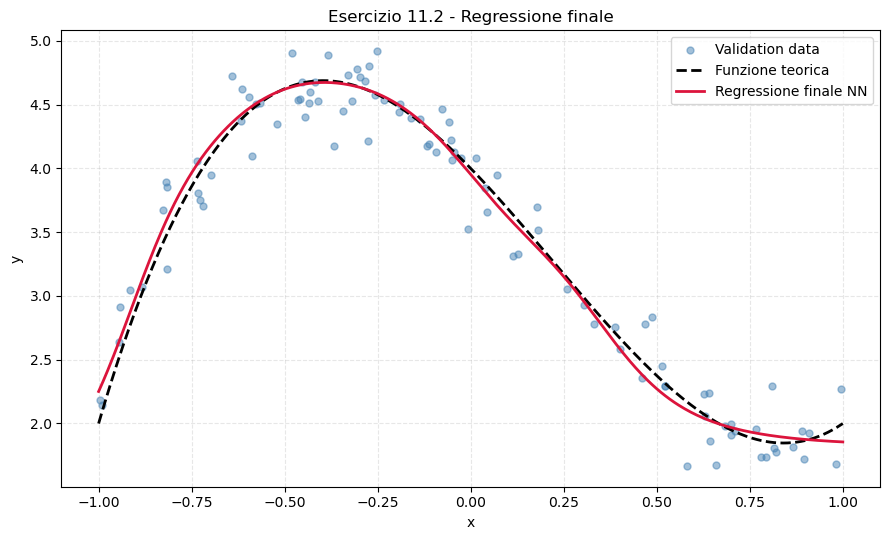

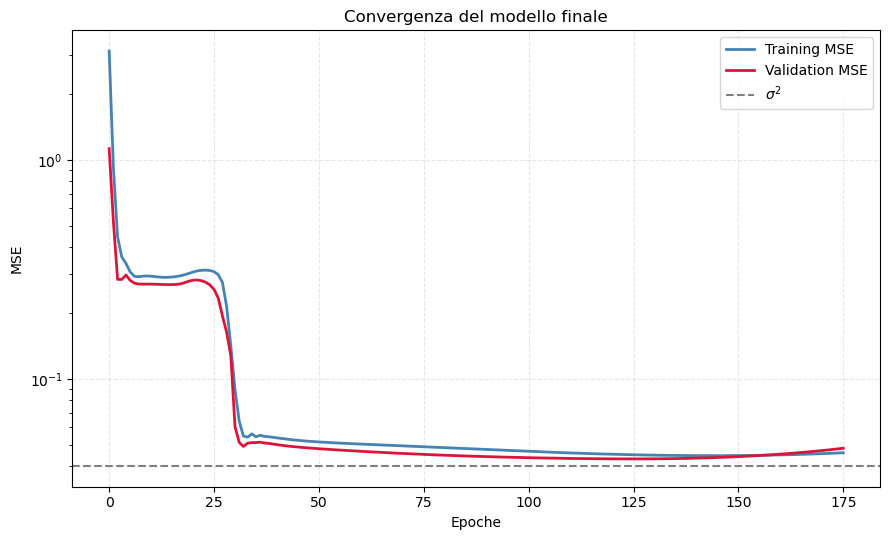

In [26]:
# ============================================================
# Risultati finali - Esercizio 11.2
# ============================================================

# Predizioni nell'intervallo di training
y_pred_poly_final = model_poly_final.predict(
    x_plot_poly.reshape(-1, 1), verbose=0
).flatten()

# Errori
train_eval = model_poly_final.evaluate(
    x_train_poly_nn, y_train_poly,
    verbose=0, return_dict=True
)

valid_eval = model_poly_final.evaluate(
    x_valid_poly_nn, y_valid_poly,
    verbose=0, return_dict=True
)

mse_theory_final = np.mean((y_plot_poly - y_pred_poly_final)**2)

# Stampa dei risultati
print("RISULTATI FINALI - ESERCIZIO 11.2")
print("-" * 45)
print(f"Epoche effettive: {len(history_poly_final.history['loss'])}")
print(f"Training MSE:     {train_eval['mse']:.6f}")
print(f"Validation MSE:   {valid_eval['mse']:.6f}")
print(f"MSE rispetto a f(x): {mse_theory_final:.6f}")

# Grafico finale
plt.figure(figsize=(9, 5.5))

plt.scatter(x_valid_poly, y_valid_poly,
            color='steelblue', s=25, alpha=0.5,
            label='Validation data')

plt.plot(x_plot_poly, y_plot_poly,
         'k--', linewidth=2, label='Funzione teorica')

plt.plot(x_plot_poly, y_pred_poly_final,
         color='crimson', linewidth=2,
         label='Regressione finale NN')

plt.xlabel('x')
plt.ylabel('y')
plt.title('Esercizio 11.2 - Regressione finale')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.3)
plt.tight_layout()
plt.show()

# Convergenza
plt.figure(figsize=(9, 5.5))

plt.plot(history_poly_final.history['mse'],
         color='steelblue', linewidth=2, label='Training MSE')

plt.plot(history_poly_final.history['val_mse'],
         color='crimson', linewidth=2, label='Validation MSE')

plt.axhline(sigma_poly**2, color='gray',
            linestyle='--', label=r'$\sigma^2$')

plt.yscale('log')
plt.xlabel('Epoche')
plt.ylabel('MSE')
plt.title('Convergenza del modello finale')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.3)
plt.tight_layout()
plt.show()

### Risultati della regressione finale

La rete selezionata è stata addestrata utilizzando 500 osservazioni di training e 100 di validazione, con rumore gaussiano di deviazione standard $\sigma=0.2$.

L'addestramento è stato effettuato con batch size pari a 32 ed Early Stopping, con patience di 50 epoche e ripristino dei pesi migliori.

I risultati finali sono:

| Quantità | Risultato |
|---|---:|
| Epoche eseguite | 176 |
| Training MSE | 0.042637 |
| Validation MSE | 0.043083 |
| MSE rispetto alla funzione teorica | 0.004461 |
| Varianza teorica del rumore $\sigma^2$ | 0.040000 |

Il Training MSE e il Validation MSE risultano molto vicini alla varianza teorica del rumore e non presentano differenze significative, indicando una buona capacità di generalizzazione nell'intervallo studiato.

Anche l'MSE rispetto alla funzione esatta risulta contenuto, confermando la capacità della rete di riprodurre il polinomio nonostante la presenza di rumore statistico.

### Interpolazione ed estrapolazione

Le analisi hanno inoltre evidenziato una marcata differenza tra interpolazione ed estrapolazione.

Nell'intervallo di training $[-1,1]$, le reti esaminate riescono ad approssimare accuratamente la funzione polinomiale. Al di fuori di tale intervallo, invece, le predizioni possono discostarsi notevolmente dall'andamento teorico.

In particolare, le reti con attivazioni saturanti come `tanh` e `sigmoid` non riproducono necessariamente la crescita cubica della funzione per valori di $|x|$ elevati.

### Conclusioni

L'esercizio ha mostrato che **una maggiore complessità della rete non garantisce automaticamente una migliore accuratezza**.

L'architettura selezionata, composta da **2 hidden layer da 8 neuroni, attivazione tanh, ottimizzatore SGD con momentum e loss MSE**, costituisce una soluzione ragionevole tra quelle testate.

L'Early Stopping ha inoltre permesso di limitare il numero di epoche, conservando i pesi associati al migliore risultato di validazione.

La configurazione scelta fornisce una buona regressione nell'intervallo di training, pur non garantendo un'accurata estrapolazione al di fuori di esso.



---

# Esercizio 11.3 — Regressione di una funzione bidimensionale

## Obiettivo

Si vuole approssimare mediante una rete neurale la funzione:

$$
f(x,y)=\sin(x^2+y^2)
$$

definita nel dominio:

$$
x,y\in[-1.5,1.5]
$$

A differenza degli esercizi precedenti, la rete presenta **2 neuroni di input**, corrispondenti alle variabili $x$ e $y$, e **1 neurone di output**, corrispondente al valore della funzione.

## Procedura

1. Generazione e visualizzazione dei dati bidimensionali, con rumore gaussiano.
2. Costruzione e addestramento della rete neurale.
3. Confronto tra superficie teorica e superficie appresa.
4. Valutazione degli errori e della capacità di generalizzazione.

Si partirà da un'architettura simile a quella selezionata nell'Esercizio 11.2, verificando se risulta sufficientemente accurata anche per una funzione di due variabili.





### Dataset

| Parametro | Valore |
|---|---|
| Training set | 6000 punti |
| Validation set | 1200 punti |
| Dominio | $[-1.5,1.5]^2$ |
| Deviazione standard del rumore | $\sigma=0.2$ |
| Varianza del rumore | $\sigma^2=0.04$ |

### Architettura della rete neurale

Si utilizza come punto di partenza l'architettura selezionata nell'Esercizio 11.2, adattandola alla presenza di due variabili indipendenti.

| Parametro | Valore |
|---|---|
| Input layer | 2 neuroni |
| Hidden layer | 2 |
| Neuroni per hidden layer | 8 + 8 |
| Funzione di attivazione | `tanh` |
| Output layer | 1 neurone, attivazione `linear` |
| Parametri addestrabili | 105 |
| Ottimizzatore | SGD con momentum |
| Learning rate | 0.05 |
| Momentum | 0.9 |
| Loss function | MSE |
| Epoche massime | 200 |
| Batch size | 64 |
| Early Stopping | Patience = 40, monitoraggio `val_loss` |

L'obiettivo è verificare se un'architettura relativamente semplice riesca ad approssimare una funzione non lineare di due variabili, mantenendo una buona capacità di generalizzazione.


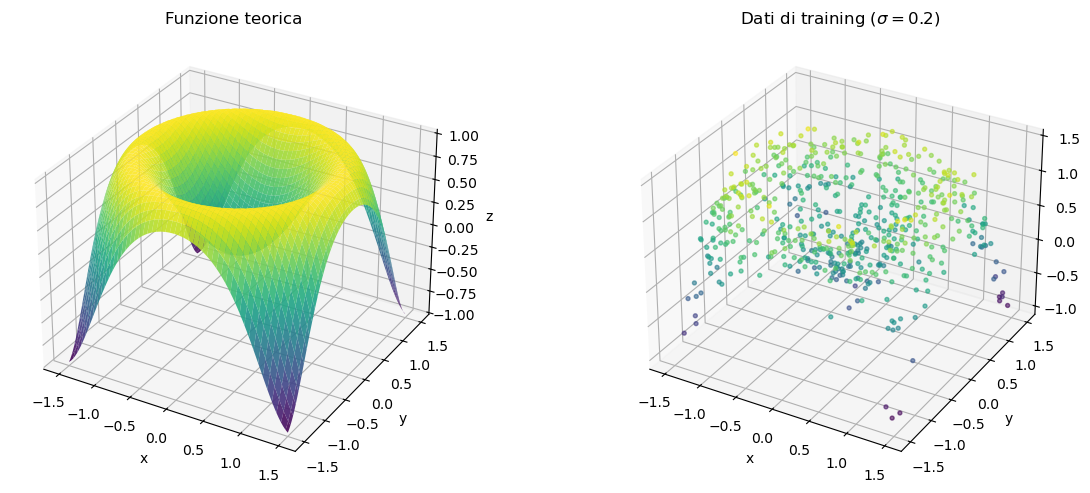

In [42]:

# ============================================================
# ESERCIZIO 11.3 - Regressione bidimensionale
# ============================================================

# Funzione teorica
def f_2d(x, y):
    return np.sin(x**2 + y**2)

# Parametri
N_train_2d = 6000
N_valid_2d = 1200
sigma_2d = 0.2

rng_2d = np.random.default_rng(113)

# Generazione degli input (x, y)
X_train_2d = rng_2d.uniform(-1.5, 1.5, (N_train_2d, 2))
X_valid_2d = rng_2d.uniform(-1.5, 1.5, (N_valid_2d, 2))

# Valori della funzione con rumore gaussiano
z_train_2d = f_2d(X_train_2d[:, 0], X_train_2d[:, 1])
z_train_2d += rng_2d.normal(0, sigma_2d, N_train_2d)

z_valid_2d = f_2d(X_valid_2d[:, 0], X_valid_2d[:, 1])
z_valid_2d += rng_2d.normal(0, sigma_2d, N_valid_2d)

# Griglia per la funzione teorica
grid_2d = np.linspace(-1.5, 1.5, 100)
xx_2d, yy_2d = np.meshgrid(grid_2d, grid_2d)
zz_2d = f_2d(xx_2d, yy_2d)

# ============================================================
# Visualizzazione 3D
# ============================================================

fig = plt.figure(figsize=(13, 5))

# Superficie teorica
ax1 = fig.add_subplot(121, projection='3d')
ax1.plot_surface(xx_2d, yy_2d, zz_2d,
                 cmap='viridis', alpha=0.9)
ax1.set_title('Funzione teorica')

# Dati rumorosi (sottoinsieme per leggibilità)
ax2 = fig.add_subplot(122, projection='3d')
ax2.scatter(X_train_2d[:600, 0],
            X_train_2d[:600, 1],
            z_train_2d[:600],
            c=z_train_2d[:600],
            cmap='viridis', s=8, alpha=0.6)
ax2.set_title(r'Dati di training ($\sigma=0.2$)')

for ax in [ax1, ax2]:
    ax.set_xlabel('x')
    ax.set_ylabel('y')
    ax.set_zlabel('z')

plt.tight_layout()
plt.show()


Parametri addestrabili: 105
Epoche eseguite: 103
Epoca migliore: 63
Training MSE: 0.041634
Validation MSE: 0.040617
Varianza rumore: 0.040000


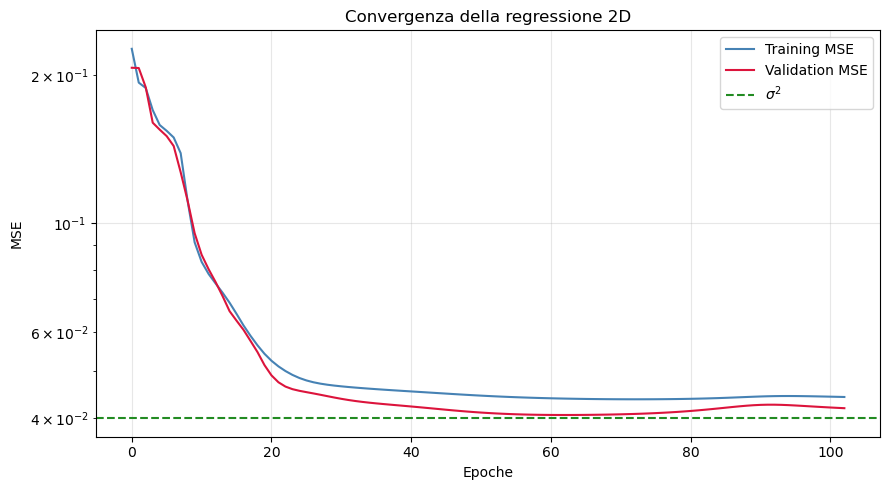

In [43]:

# ============================================================
# ESERCIZIO 11.3 - Costruzione e addestramento della rete
# ============================================================

keras.utils.set_random_seed(42)

# Architettura: 2 input, 2 hidden layer, 1 output
model_2d = keras.Sequential([
    keras.Input(shape=(2,)),
    keras.layers.Dense(8, activation='tanh'),
    keras.layers.Dense(8, activation='tanh'),
    keras.layers.Dense(1, activation='linear')
])

# Compilazione
model_2d.compile(
    optimizer=keras.optimizers.SGD(
        learning_rate=0.05, momentum=0.9
    ),
    loss='mse'
)

# Early Stopping
early_stop_2d = keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=40,
    restore_best_weights=True
)

# Addestramento
history_2d = model_2d.fit(
    X_train_2d, z_train_2d,
    epochs=200,
    batch_size=64,
    validation_data=(X_valid_2d, z_valid_2d),
    callbacks=[early_stop_2d],
    shuffle=True,
    verbose=0
)

# Valutazione finale
train_mse_2d = model_2d.evaluate(
    X_train_2d, z_train_2d, verbose=0
)

valid_mse_2d = model_2d.evaluate(
    X_valid_2d, z_valid_2d, verbose=0
)

print(f"Parametri addestrabili: {model_2d.count_params()}")
print(f"Epoche eseguite: {len(history_2d.history['loss'])}")
print(f"Epoca migliore: {np.argmin(history_2d.history['val_loss']) + 1}")
print(f"Training MSE: {train_mse_2d:.6f}")
print(f"Validation MSE: {valid_mse_2d:.6f}")
print(f"Varianza rumore: {sigma_2d**2:.6f}")

# Convergenza
plt.figure(figsize=(9, 5))

plt.plot(history_2d.history['loss'],
         label='Training MSE', color='steelblue')

plt.plot(history_2d.history['val_loss'],
         label='Validation MSE', color='crimson')

plt.axhline(sigma_2d**2, color='forestgreen',
            linestyle='--', label=r'$\sigma^2$')

plt.xlabel('Epoche')
plt.ylabel('MSE')
plt.title('Convergenza della regressione 2D')
plt.yscale('log')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


Punti di training:    6000
Punti di validazione: 1200


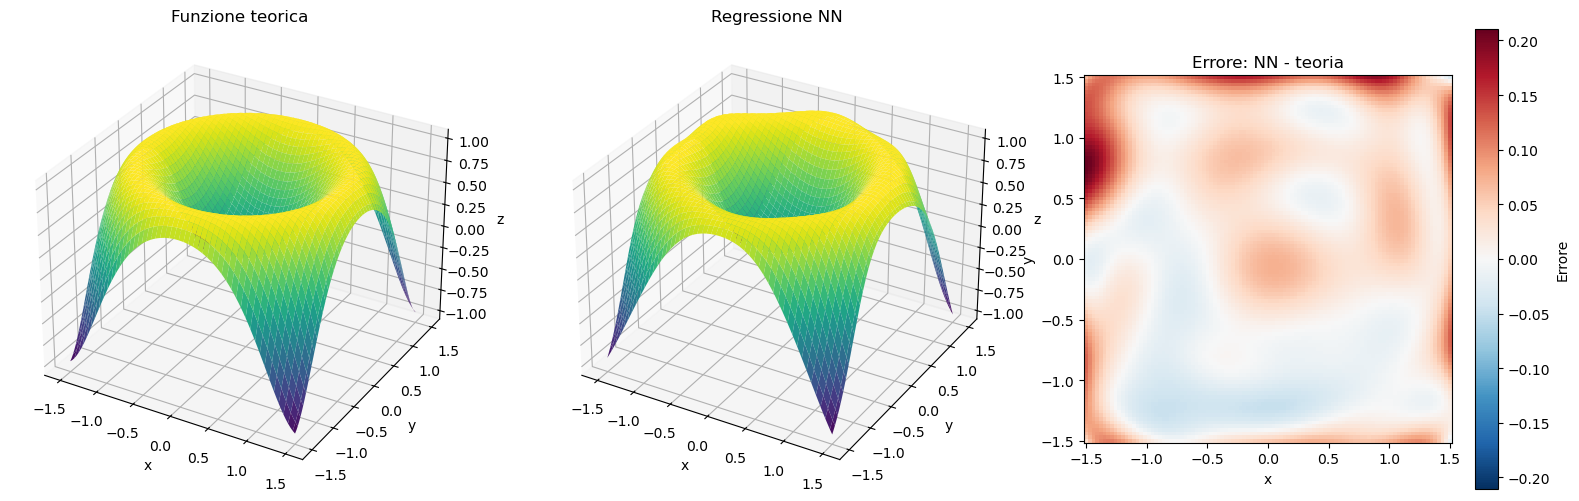

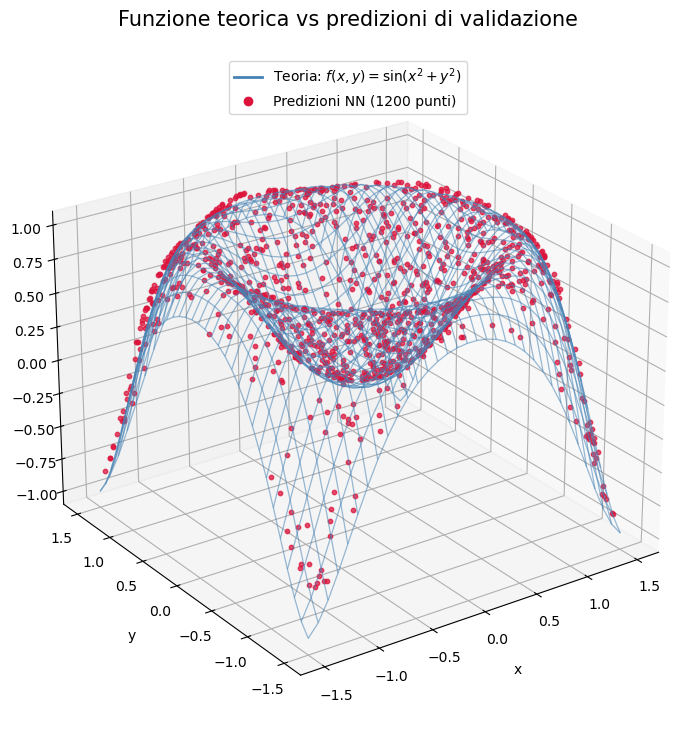


RISULTATI FINALI - ESERCIZIO 11.3
--------------------------------------------------
Training MSE:             0.041634
Validation MSE:           0.040617
Varianza del rumore:      0.040000

MSE teorico sulla griglia: 0.002152
RMSE teorico:             0.046388
Errore massimo:           0.210476

MSE teorico sui 1200 punti di validazione: 0.002281


In [49]:

# ============================================================
# ESERCIZIO 11.3 - Confronto finale tra teoria e regressione NN
# ============================================================

from matplotlib.lines import Line2D

# Verifica delle dimensioni dei dataset
print(f"Punti di training:    {len(X_train_2d)}")
print(f"Punti di validazione: {len(X_valid_2d)}")

# ============================================================
# Calcolo degli errori con il modello aggiornato
# ============================================================

# MSE sui dati rumorosi
train_mse_2d = model_2d.evaluate(
    X_train_2d, z_train_2d, verbose=0
)

valid_mse_2d = model_2d.evaluate(
    X_valid_2d, z_valid_2d, verbose=0
)

# Preparazione della griglia regolare
X_grid_2d = np.column_stack([
    xx_2d.ravel(),
    yy_2d.ravel()
])

# Funzione teorica e predizioni sulla griglia
zz_2d = f_2d(xx_2d, yy_2d)

zz_pred_2d = model_2d.predict(
    X_grid_2d, verbose=0
).reshape(xx_2d.shape)

# Errore rispetto alla funzione esatta
error_2d = zz_pred_2d - zz_2d

mse_theory_2d = np.mean(error_2d**2)
rmse_theory_2d = np.sqrt(mse_theory_2d)
max_err = np.max(np.abs(error_2d))

# ============================================================
# Predizioni sui 1200 punti indipendenti di validazione
# ============================================================

z_valid_pred = model_2d.predict(
    X_valid_2d, verbose=0
).flatten()

# Valori teorici senza rumore sugli stessi punti
z_valid_true = f_2d(
    X_valid_2d[:, 0],
    X_valid_2d[:, 1]
)

# MSE delle predizioni rispetto ai valori teorici esatti
mse_valid_theory = np.mean(
    (z_valid_pred - z_valid_true)**2
)

# ============================================================
# GRAFICO 1 - Superfici teorica, predetta e mappa degli errori
# ============================================================

fig = plt.figure(figsize=(16, 5))

# Superficie teorica
ax1 = fig.add_subplot(131, projection='3d')
ax1.plot_surface(
    xx_2d, yy_2d, zz_2d,
    cmap='viridis', vmin=-1, vmax=1
)
ax1.set_title('Funzione teorica')

# Superficie appresa dalla rete
ax2 = fig.add_subplot(132, projection='3d')
ax2.plot_surface(
    xx_2d, yy_2d, zz_pred_2d,
    cmap='viridis', vmin=-1, vmax=1
)
ax2.set_title('Regressione NN')

for ax in [ax1, ax2]:
    ax.set_xlabel('x')
    ax.set_ylabel('y')
    ax.set_zlabel('z')
    ax.set_zlim(-1.1, 1.1)
    ax.view_init(elev=30, azim=-60)

# Mappa dell'errore
ax3 = fig.add_subplot(133)

im = ax3.pcolormesh(
    xx_2d, yy_2d, error_2d,
    cmap='RdBu_r',
    vmin=-max_err,
    vmax=max_err,
    shading='auto'
)

ax3.set_xlabel('x')
ax3.set_ylabel('y')
ax3.set_title('Errore: NN - teoria')
ax3.set_aspect('equal')

fig.colorbar(im, ax=ax3, label='Errore')

plt.tight_layout()
plt.show()


# ============================================================
# GRAFICO 2 - Wireframe teorico + 1200 predizioni di validazione
# ============================================================

# Griglia ridotta soltanto per disegnare il wireframe
step = 3

xx_plot = xx_2d[::step, ::step]
yy_plot = yy_2d[::step, ::step]
zz_true_plot = f_2d(xx_plot, yy_plot)

fig = plt.figure(figsize=(11, 7.5))
ax = fig.add_subplot(111, projection='3d')

# Funzione teorica: wireframe azzurro
ax.plot_wireframe(
    xx_plot, yy_plot, zz_true_plot,
    rstride=1, cstride=1,
    color='steelblue',
    linewidth=0.9,
    alpha=0.55
)

# Predizioni sui punti del validation set
ax.scatter(
    X_valid_2d[:, 0],
    X_valid_2d[:, 1],
    z_valid_pred,
    color='crimson',
    s=10,
    alpha=0.75,
    depthshade=False
)

ax.set_title('Funzione teorica vs predizioni di validazione',
             fontsize=15, pad=20)

ax.set_xlabel('x', labelpad=10)
ax.set_ylabel('y', labelpad=10)
ax.set_zlabel('z', labelpad=10)

ax.set_zlim(-1.1, 1.1)
ax.view_init(elev=25, azim=-125)

# Legenda
legend_elements = [
    Line2D([0], [0], color='steelblue', lw=2,
           label=r'Teoria: $f(x,y)=\sin(x^2+y^2)$'),

    Line2D([0], [0], marker='o', linestyle='None',
           color='crimson', markersize=6,
           label=f'Predizioni NN ({len(X_valid_2d)} punti)')
]

ax.legend(
    handles=legend_elements,
    loc='upper center',
    fontsize=10
)

plt.tight_layout()
plt.show()


# ============================================================
# RISULTATI FINALI
# ============================================================

print("\nRISULTATI FINALI - ESERCIZIO 11.3")
print("-" * 50)

print(f"Training MSE:             {train_mse_2d:.6f}")
print(f"Validation MSE:           {valid_mse_2d:.6f}")
print(f"Varianza del rumore:      {sigma_2d**2:.6f}")

print(f"\nMSE teorico sulla griglia: {mse_theory_2d:.6f}")
print(f"RMSE teorico:             {rmse_theory_2d:.6f}")
print(f"Errore massimo:           {max_err:.6f}")

print(f"\nMSE teorico sui {len(X_valid_2d)} punti di validazione: "
      f"{mse_valid_theory:.6f}")


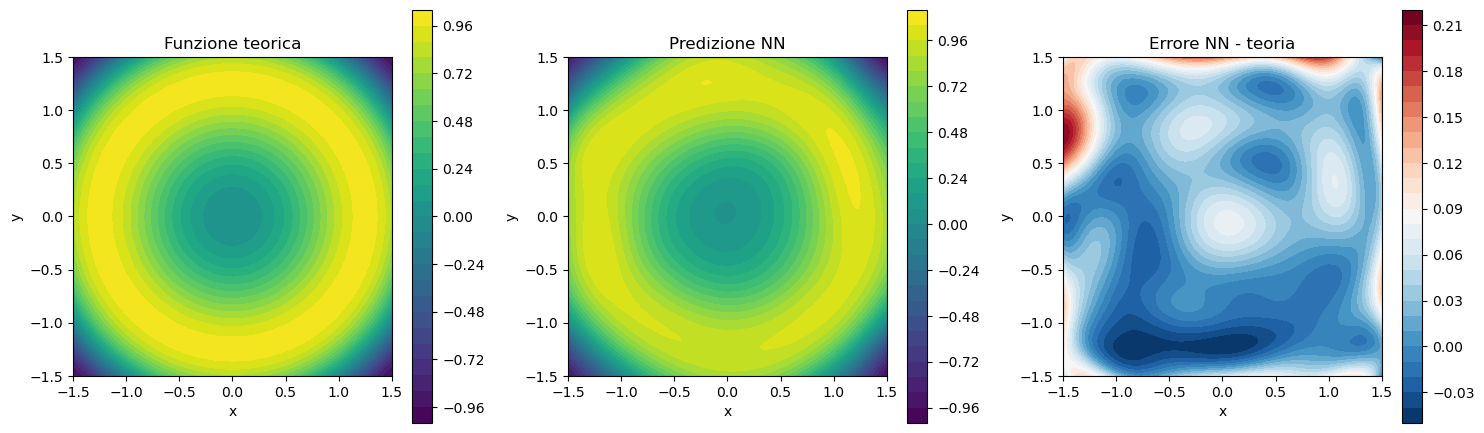

In [50]:
# ============================================================
# Mappe di contorno: teoria, predizione, errore
# ============================================================

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

# Teoria
c1 = axes[0].contourf(xx_2d, yy_2d, zz_2d, levels=25, cmap='viridis')
axes[0].set_title('Funzione teorica')
axes[0].set_xlabel('x')
axes[0].set_ylabel('y')
axes[0].set_aspect('equal')
fig.colorbar(c1, ax=axes[0])

# Predizione
c2 = axes[1].contourf(xx_2d, yy_2d, zz_pred_2d, levels=25, cmap='viridis')
axes[1].set_title('Predizione NN')
axes[1].set_xlabel('x')
axes[1].set_ylabel('y')
axes[1].set_aspect('equal')
fig.colorbar(c2, ax=axes[1])

# Errore
c3 = axes[2].contourf(xx_2d, yy_2d, error_2d, levels=25, cmap='RdBu_r')
axes[2].set_title('Errore NN - teoria')
axes[2].set_xlabel('x')
axes[2].set_ylabel('y')
axes[2].set_aspect('equal')
fig.colorbar(c3, ax=axes[2])

plt.tight_layout()
plt.show()


## Risultati e conclusioni dell'Esercizio 11.3

La funzione $f(x,y)=\sin(x^2+y^2)$ è stata approssimata mediante una rete neurale con **2 hidden layer da 8 neuroni**, attivazione `tanh`, ottimizzatore SGD con momentum e loss MSE.

Sono stati utilizzati **6000 punti di training** e **1200 punti di validazione**, con rumore gaussiano di deviazione standard $\sigma=0.2$.

### Risultati

| Quantità | Valore |
|---|---:|
| Parametri addestrabili | 105 |
| Epoche eseguite | 103 |
| Epoca migliore | 63 |
| Training MSE | 0.041634 |
| Validation MSE | 0.040617 |
| Varianza del rumore $\sigma^2$ | 0.040000 |
| MSE rispetto alla funzione teorica (griglia ridotta) | $\approx 0.002530$ |
| RMSE rispetto alla funzione teorica (griglia ridotta) | $\approx 0.0503$ |

### Analisi dei risultati

Il Training MSE e il Validation MSE risultano molto vicini alla varianza del rumore $\sigma^2=0.04$, senza evidenziare fenomeni significativi di overfitting.

L'errore rispetto alla funzione teorica è invece nettamente inferiore, indicando che la rete riesce a ricostruire la struttura della funzione senza riprodurre le fluttuazioni casuali dei dati.

Le visualizzazioni tridimensionali e le mappe di contorno confermano una buona ricostruzione della simmetria radiale, con scostamenti più evidenti in prossimità dei bordi del dominio.

### Conclusioni

L'architettura selezionata permette di approssimare accuratamente una funzione non lineare di due variabili, mantenendo un numero relativamente contenuto di parametri.

L'Early Stopping consente inoltre di interrompere l'addestramento dopo 103 epoche, recuperando i pesi corrispondenti all'epoca 63.

Nonostante l'introduzione di un rumore gaussiano significativo rispetto alla scala della funzione $\sigma=0.2$, la rete riesce a ricostruire il segnale teorico con un RMSE di circa \(0.05\), nettamente inferiore alla dispersione delle osservazioni. Questo evidenzia la capacità del modello di apprendere la struttura della funzione senza adattarsi alle singole fluttuazioni statistiche.

**In conclusione**, la rete presenta una buona capacità di generalizzazione e un errore rispetto alla funzione esatta significativamente inferiore a quello dovuto al rumore statistico.
